# Phase 3 — Pattern Spotting
## Patterns of Recorded Civilian Targeting in Gaza

**DS312 · Group 7 · Phase 3 EDA, Task 5: segments, trends, seasonality, suspicious values and class imbalance**

> **Where this section sits.** Tasks 1 to 3 (univariate, bivariate/multivariate, visualisation) and Task 4 (hypothesis tests) are already written by teammates. This notebook does **not** repeat their charts or tests. It uses the same four Phase 2 tables, the same filters and the same definitions, and then looks for what *stands out*: unusual values, shifts over time, repeating (or non-repeating) cycles, groups of districts, weeks and places, and lopsided classes. Every number that overlaps with an earlier task is checked against it in Section 2.

## 1. Purpose, scope and reading guide

### What "pattern spotting" covers here
The task tracker asks for an **outliers, trends, clustering and imbalance report**. We split it into five questions, each tied to a Phase 1 business question (BQ) and to a Phase 2 table.

| Pattern type | Question | Table (unit of analysis) | Section | Charts |
|---|---|---|---|---|
| **Class imbalance** | Where is focal vs. not-focal so lopsided that a comparison or model would struggle? | `acled_events_clean.csv` (one event), `acled_district_week.csv` | 3 | 1 |
| **Suspicious values** | Which fatality totals and which weeks stand far from typical, and is the data itself consistent? | `acled_events_clean.csv`, `acled_gaza_week.csv`, `acled_district_week.csv` | 4 | 2, 3, 4 |
| **Trends** | Do focal counts and focal share move in one direction over the two years? | `acled_gaza_week.csv` (one Gaza week) | 5 | 5 |
| **Seasonality and persistence** | Do the same months or weekdays repeat, and does a week resemble the previous ones? | `acled_gaza_week.csv`, `acled_events_clean.csv` | 6 | 6, 7 |
| **Segments and clustering** | Which districts, kinds of weeks and places group together? | `acled_district_week.csv`, `acled_gaza_week.csv`, `acled_focal_incidents.csv` | 7 | 8, 9, 10, 11, 12 |

### Interpretation boundary
Everything here describes **records coded by ACLED** and the project's focal-event rule. An outlier, a cluster, a trend or a flagged week is **not** proof of intent, responsibility, causation or legal classification, and a quiet week is not proof that no harm happened. Where a chart shows a dip or a spike we describe it and say what the files cannot tell us; we do not explain its cause.

### Rules carried over from the earlier tasks
- Focal shares always use **political-violence records** as the denominator.
- All Gaza events stay in event-level and Gaza-wide numbers; the **4 events with no district** are left out only of district tables, and **coast-coded events** only of the land spatial table.
- The final week (week of Sep 27, 2025) is **incomplete**, so it is shown but not scored.
- High-fatality flags are for review and **never delete a record**. Precision codes are categories, not distances.
- A week or district with zero recorded events means zero *recorded* events.

### What is reused from the other tasks (numbers only, no tests)
Task 1: fatality percentiles and the focal / not-focal counts. Task 2: focal share before and after Oct 7 (16.2% and 47.6%), by event type and by precision. Task 3: the district-week heatmap and weekly count/share charts. **Task 4 (hypothesis tests) is cited, not repeated:** where imbalance matters for a test, we point to Sections 4.3 and 4.4 of that notebook.

## 2. Setup, data loading and consistency checks

The notebook looks for the four Phase 2 CSVs in `data/processed/` (the team layout) or in a `Data_Stores/` folder (the layout used locally), searching the working folder and its parents. If yours sit somewhere else, set `DATA_DIR` in the second cell. Dates are parsed and the two precision codes are restored as ordered categories, as in the other notebooks. `scikit-learn` is needed for the clustering previews in Section 7 (`pip install scikit-learn`); it is not in the Phase 2 requirements file.

In [1]:
# Windows fix: these must be set BEFORE numpy/scikit-learn are imported (restart the kernel if you add them later).
# They stop the harmless "physical cores" and "KMeans memory leak (MKL)" warnings on Windows.
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))
import warnings
warnings.filterwarnings("ignore", message=".*physical cores.*")
warnings.filterwarnings("ignore", message=".*memory leak on Windows.*")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.fontsize": 9})
plt.rcParams["axes.grid.axis"] = "y"   # horizontal gridlines only; maps and horizontal bars adjust below

SEED = 42
np.random.seed(SEED)

# Same colour logic as the teammates' notebooks: focal = dark red, other = blue, context = grey
C_FOCAL, C_OTHER, C_GREY, C_WARN = "#8D3B42", "#315A7D", "#9AA5B1", "#E0A458"

In [2]:
# The notebook looks for the four Phase 2 CSVs in data/processed/ (the team layout) or in a
# Data_Stores/ folder (your local layout), in the working folder and its parents.
# If yours are somewhere else, set DATA_DIR by hand, e.g. DATA_DIR = Path(r"C:\\path\\to\\Data_Stores")
DATA_DIR = None

def find_data_dir(filename="acled_events_clean.csv"):
    for base in [Path.cwd(), *Path.cwd().parents]:
        for sub in ("data/processed", "Data_Stores", "data", "."):
            candidate = base / sub
            if (candidate / filename).is_file():
                return candidate
    raise FileNotFoundError("Could not find the Phase 2 CSVs. Put this notebook next to the folder that "
                            "holds them (data/processed/ or Data_Stores/), or set DATA_DIR above.")

DATA_DIR = Path(DATA_DIR) if DATA_DIR else find_data_dir()
print("Reading Phase 2 outputs from:", DATA_DIR.resolve())

# Event-level master (Gaza, Jan 2022 to Sep 2025)
master = pd.read_csv(DATA_DIR / "acled_events_clean.csv",
                     parse_dates=["event_date", "month_start", "week_start"])
for col in ("geo_precision", "time_precision"):
    master[col] = pd.Categorical(master[col], categories=[1, 2, 3], ordered=True)

# Weekly tables (Oct 7, 2023 onward)
gaza_week = pd.read_csv(DATA_DIR / "acled_gaza_week.csv", parse_dates=["week_start", "week_end"])
district_week = pd.read_csv(DATA_DIR / "acled_district_week.csv", parse_dates=["week_start", "week_end"])

# Land-based focal incidents (Oct 7, 2023 onward; coast-coded events excluded)
incidents = pd.read_csv(DATA_DIR / "acled_focal_incidents.csv", parse_dates=["event_date", "month_start", "week_start"])
for col in ("geo_precision", "time_precision"):
    incidents[col] = pd.Categorical(incidents[col], categories=[1, 2, 3], ordered=True)

print("master:", master.shape, "| gaza_week:", gaza_week.shape,
      "| district_week:", district_week.shape, "| incidents:", incidents.shape)

Reading Phase 2 outputs from: C:\Users\Ashlanie\Documents\3RD YEAR 1ST SEM\DMA\DMA FINAL PIT\Data_Stores
master: (26664, 43) | gaza_week: (104, 13) | district_week: (520, 14) | incidents: (10583, 45)


The next cell defines the periods and the political-violence denominator and compares what was loaded with the figures the teammates' notebooks quote. If any row says `False`, stop and check the file versions before using any result below.

In [3]:
# Period definitions follow Phase 2: Oct 7, 2023 is the cut-off; the two periods differ in length.
BEFORE, AFTER = "Before Oct 7, 2023", "Oct 7, 2023 onward"
CUTOFF = pd.Timestamp("2023-10-07")

# Political-violence records are the denominator for every focal share (same as Tasks 2 and 4)
political = master.loc[master.political_violence].copy()

# Integrity check: compare what we loaded with the figures the teammates' notebooks quote.
checks = pd.DataFrame([
    ("Event master shape", (26664, 43), master.shape),
    ("Gaza-week table shape", (104, 13), gaza_week.shape),
    ("District-week table shape", (520, 14), district_week.shape),
    ("Focal-incident table shape", (10583, 45), incidents.shape),
    ("Focal events, all", 10714, int(master.focal_event.sum())),
    ("Focal events before Oct 7", 63, int(master.loc[master.period == BEFORE, "focal_event"].sum())),
    ("Focal events Oct 7 onward", 10651, int(master.loc[master.period == AFTER, "focal_event"].sum())),
    ("Political-violence records before Oct 7", 389, int((political.period == BEFORE).sum())),
    ("Political-violence records Oct 7 onward", 22364, int((political.period == AFTER).sum())),
    ("Events with no district", 4, int(master.admin2.isna().sum())),
    ("Gaza-week focal total", 10651, int(gaza_week.focal_events.sum())),
    ("District-week focal total (3 focal events lack a district)", 10648, int(district_week.focal_events.sum())),
    ("Incomplete weeks in Gaza-week table", 1, int((~gaza_week.complete_week).sum())),
    ("Land focal incidents", 10583, len(incidents)),
    ("Precision-1 land focal incidents", 7576, int(incidents.geo_precision_1.sum())),
], columns=["Check", "Expected", "Observed"])
checks["Match"] = [e == o for e, o in zip(checks["Expected"], checks["Observed"])]
display(checks)
print("All checks match the earlier tasks." if checks.Match.all()
      else "Some checks differ: review the table above before using the results.")

,Check,Expected,Observed,Match
0,Event master shape,"(26664, 43)","(26664, 43)",True
1,Gaza-week table shape,"(104, 13)","(104, 13)",True
2,District-week table shape,"(520, 14)","(520, 14)",True
3,Focal-incident table shape,"(10583, 45)","(10583, 45)",True
4,"Focal events, all",10714,10714,True
5,Focal events before Oct 7,63,63,True
6,Focal events Oct 7 onward,10651,10651,True
7,Political-violence records before Oct 7,389,389,True
8,Political-violence records Oct 7 onward,22364,22364,True
9,Events with no district,4,4,True


All checks match the earlier tasks.


Two small helpers are used in Section 4 onward. `robust_z` is the *modified z-score*, which uses the median and the median absolute deviation (MAD) instead of the mean and standard deviation, so the very peaks we are looking for do not hide themselves. `trailing_robust_z` scores each week only against the **previous 8 weeks**, which is the baseline idea Phase 4 plans to use (trailing median/MAD). A score beyond ±3.5 is the usual rule of thumb for "unusual"; it is a screening rule, not a test.

In [4]:
Z_CUT = 3.5   # conventional cut-off for the modified (robust) z-score

def robust_z(s):
    """Modified z-score: 0.6745 * (x - median) / MAD. Robust to the very peaks we are trying to find."""
    med = s.median()
    mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad

def trailing_robust_z(s, window=8, mad_floor=1.0):
    """Score each week against the previous `window` weeks only (median/MAD of its own recent history).
    The first `window` weeks have no score. mad_floor stops a flat history from dividing by zero."""
    vals = s.to_numpy(float)
    out = np.full(len(vals), np.nan)
    for i in range(window, len(vals)):
        hist = vals[i - window:i]
        med = np.median(hist)
        mad = max(np.median(np.abs(hist - med)), mad_floor)
        out[i] = 0.6745 * (vals[i] - med) / mad
    return pd.Series(out, index=s.index)

## 3. Class imbalance

**Question.** Overall, focal events are 47.1% of political-violence records, which looks balanced. But Phase 4 will compare periods, event types and precision levels, and some of those slices are far from balanced. Where, and how thin is the smaller class? The table gives the focal share, the size of the smaller class and the majority-to-minority ratio for each slice. The weekly view at the bottom checks how often a week or a district-week is "empty".

*Source table: `master` (political-violence records) and the weekly tables. Unit: one record, one week, one district-week.*

In [5]:
def imbalance_row(label, df):
    n = len(df); k = int(df.focal_event.sum()); minority = min(k, n - k)
    return {"Slice": label, "Records": n, "Focal": k, "Not focal": n - k,
            "Focal share": k / n, "Minority class": "focal" if k < n - k else "not focal",
            "Minority count": minority, "Majority : minority": (max(k, n - k) / minority) if minority else np.nan}

post = political[political.period == AFTER]
slices = [
    ("All political-violence records", political),
    ("Before Oct 7, 2023", political[political.period == BEFORE]),
    ("Oct 7, 2023 onward", post),
    ("Oct 7+ · precision 1", post[post.geo_precision == 1]),
    ("Oct 7+ · precision 2", post[post.geo_precision == 2]),
    ("Oct 7+ · Explosions/Remote violence", post[post.event_type == "Explosions/Remote violence"]),
    ("Oct 7+ · Violence against civilians", post[post.event_type == "Violence against civilians"]),
    ("Oct 7+ · Battles", post[post.event_type == "Battles"]),
]
imb = pd.DataFrame([imbalance_row(l, d) for l, d in slices]).set_index("Slice")
display(imb.round({"Focal share": 3, "Majority : minority": 2}))

# Weekly view of the same question: how often is a week "quiet" for focal events?
print("Weeks in the Gaza-week table:", len(gaza_week),
      "| weeks with zero political-violence records:", int((gaza_week.political_events == 0).sum()),
      "| weeks with zero focal events:", int((gaza_week.focal_events == 0).sum()))
dw_zero = district_week.assign(zero_focal=district_week.focal_events == 0,
                               zero_political=district_week.political_events == 0)
display(dw_zero.groupby("admin2")[["zero_focal", "zero_political"]].sum().rename(
    columns={"zero_focal": "district-weeks with 0 focal events", "zero_political": "district-weeks with 0 political-violence records"}))

,Records,Focal,Not focal,Focal share,Minority class,Minority count,Majority : minority
Slice,,,,,,,
All political-violence records,22753,10714,12039,0.471,focal,10714,1.12
"Before Oct 7, 2023",389,63,326,0.162,focal,63,5.17
"Oct 7, 2023 onward",22364,10651,11713,0.476,focal,10651,1.10
Oct 7+ · precision 1,12704,7577,5127,0.596,not focal,5127,1.48
Oct 7+ · precision 2,9583,3040,6543,0.317,focal,3040,2.15
Oct 7+ · Explosions/Remote violence,19978,9867,10111,0.494,focal,9867,1.02
Oct 7+ · Violence against civilians,790,784,6,0.992,not focal,6,130.67
Oct 7+ · Battles,1593,0,1593,0.000,focal,0,NaN


Weeks in the Gaza-week table: 104 | weeks with zero political-violence records: 0 | weeks with zero focal events: 0


,district-weeks with 0 focal events,district-weeks with 0 political-violence records
admin2,,
Deir El Balah,0,0
Gaza City,0,0
Khan Yunis,0,0
North Gaza,7,3
Rafah,0,0


### Chart 1 — How lopsided is each slice, and how big is the smaller class?

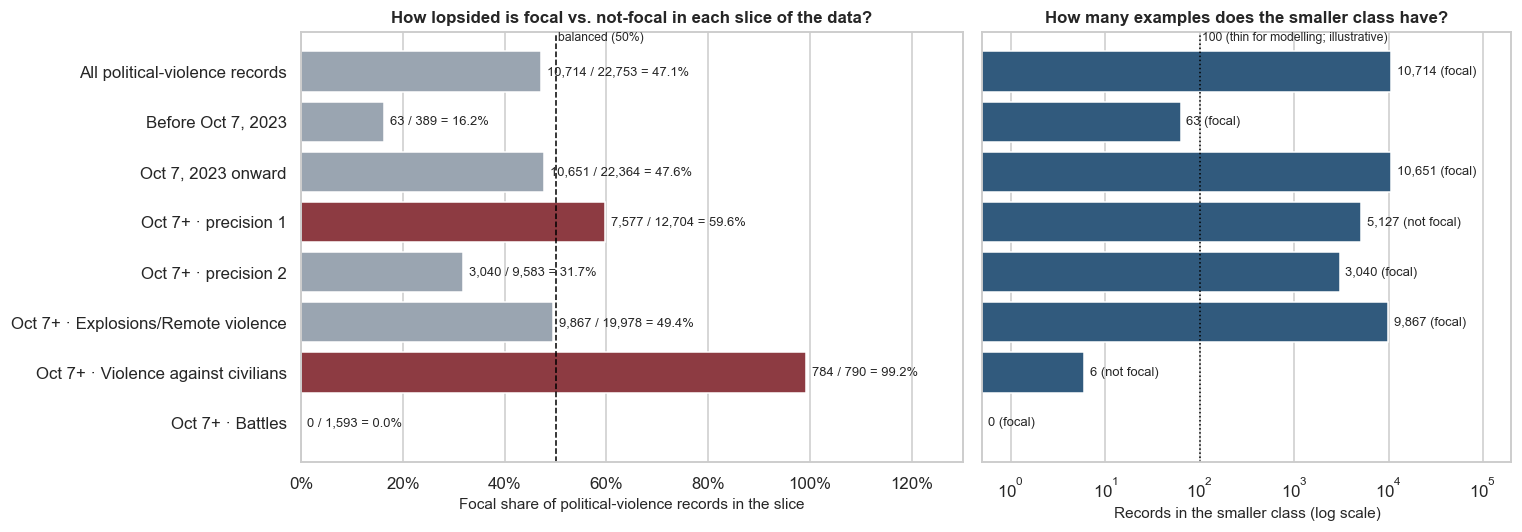

In [6]:
plot_df = imb.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.25, 1]})

ax = axes[0]
colors = [C_FOCAL if s >= 0.5 else C_GREY for s in plot_df["Focal share"]]
ax.barh(plot_df.index, plot_df["Focal share"], color=colors)
for y, (_, r) in enumerate(plot_df.iterrows()):
    ax.text(r["Focal share"] + 0.012, y, f"{r.Focal:,.0f} / {r.Records:,.0f} = {r['Focal share']:.1%}", va="center", fontsize=8.5)
ax.axvline(0.5, color="black", lw=1, ls="--")
ax.text(0.505, len(plot_df) - 0.45, "balanced (50%)", fontsize=8, va="bottom")
ax.set_xlim(0, 1.3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Focal share of political-violence records in the slice")
ax.set_ylabel("")
ax.set_title("How lopsided is focal vs. not-focal in each slice of the data?")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)

ax = axes[1]
ax.barh(plot_df.index, plot_df["Minority count"].clip(lower=0.5), color=C_OTHER)
for y, (_, r) in enumerate(plot_df.iterrows()):
    ax.text(max(r["Minority count"], 0.5) * 1.15, y, f"{r['Minority count']:,.0f} ({r['Minority class']})", va="center", fontsize=8.5)
ax.set_xscale("log"); ax.set_xlim(0.5, 2e5)
ax.axvline(100, color="black", lw=1, ls=":")
ax.text(105, len(plot_df) - 0.45, "100 (thin for modelling; illustrative)", fontsize=8, va="bottom")
ax.set_yticklabels([]); ax.set_ylabel("")
ax.set_xlabel("Records in the smaller class (log scale)")
ax.set_title("How many examples does the smaller class have?")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

**Interpretation.** The overall split is nearly even (10,714 focal of 22,753), and so is the period from Oct 7 onward (10,651 of 22,364, ratio 1.10 to 1), but the earlier period is lopsided: 63 focal of 389 records (16.2%, about 5 to 1) with only 63 examples in the smaller class (BQ1, BQ5). Inside the later period the extremes are structural: Violence against civilians is 784 of 790 focal and Battles are 0 of 1,593, so the ratio reaches 131 to 1 and one class is empty. Precision also moves the balance (59.6% focal at precision 1 against 31.7% at precision 2). The event-type extremes are partly built into the focal rule, which needs a civilian actor label, so they describe the coding as much as the events; Task 4 already tests the period and event-type differences, so this chart only shows where the smaller class is too small to model on its own.

**Weekly view.** No Gaza week has zero political-violence records or zero focal events. Only North Gaza has empty district-weeks: 7 with no focal events (6 of them in complete weeks) and 3 with no political-violence records, so shares there are undefined in those weeks. A zero is a zero *recorded* count.

## 4. Suspicious values and outliers

Three kinds of "suspicious": (a) very large fatality totals, (b) weeks whose counts are far from the usual, and (c) data-quality red flags in the files themselves. None of these is deleted; they are flagged for review.

### 4.1 Fatality outliers

**Question.** Fatalities are heavy-tailed with many zeros (Task 1 covers the distribution). Here we ask how far the tail reaches, how much of the reported total sits in it, and when and where it occurs. The review flag in the data marks records with **24 or more** reported fatalities (the lowest flagged value is 24 and the highest unflagged value is 23). Fatalities are reported event totals, not confirmed civilian deaths.

*Source table: `master`. Unit: one event record.*

In [7]:
f = master.fatalities
thr = int(master.loc[master.high_fatalities_review, "fatalities"].min())
thr_below = int(master.loc[~master.high_fatalities_review, "fatalities"].max())
flag = master[master.high_fatalities_review]
top1 = master.nlargest(int(len(master) * 0.01), "fatalities")

fat_summary = pd.DataFrame({"Value": {
    "Records": len(master),
    "Records with 0 fatalities": f"{(f == 0).sum():,} ({(f == 0).mean():.1%})",
    "Median / 75th / 90th percentile": f"{f.median():.0f} / {f.quantile(.75):.0f} / {f.quantile(.90):.0f}",
    "95th / 99th percentile": f"{f.quantile(.95):.0f} / {f.quantile(.99):.0f}",
    "Maximum": int(f.max()),
    "Mean (pulled up by the tail)": round(f.mean(), 2),
    "IQR upper fence (Q3 + 1.5 x IQR)": round(f.quantile(.75) + 1.5 * (f.quantile(.75) - f.quantile(.25)), 1),
    "Review flag: lowest flagged / highest unflagged": f"{thr} / {thr_below}",
    "Records flagged for review": f"{len(flag):,} ({len(flag) / len(master):.1%} of records)",
    "Share of all reported fatalities in flagged records": f"{flag.fatalities.sum() / f.sum():.1%}",
    "Share of all reported fatalities in the top 1% of records": f"{top1.fatalities.sum() / f.sum():.1%}",
    "Flagged records that are focal": f"{int(flag.focal_event.sum())} of {len(flag)}",
}})
display(fat_summary)

print("Flagged records by event type and focal status")
display(flag.groupby(["event_type", "focal_event"]).size().rename("flagged records").to_frame())
print("Flagged records by location precision:", flag.geo_precision.value_counts().sort_index().to_dict())

,Value
Records,26664
Records with 0 fatalities,"17,634 (66.1%)"
Median / 75th / 90th percentile,0 / 2 / 7
95th / 99th percentile,12 / 39
Maximum,471
Mean (pulled up by the tail),2.55
IQR upper fence (Q3 + 1.5 x IQR),5.0
Review flag: lowest flagged / highest unflagged,24 / 23
Records flagged for review,576 (2.2% of records)
Share of all reported fatalities in flagged records,37.6%


Flagged records by event type and focal status


flagged records
event_type                 focal_event                 
Battles                    False                     97
Explosions/Remote violence False                     57
                           True                     409
Violence against civilians True                      13

Flagged records by location precision: {1: 448, 2: 128, 3: 0}


### Chart 2 — How long is the fatality tail, and which records sit at the end of it?

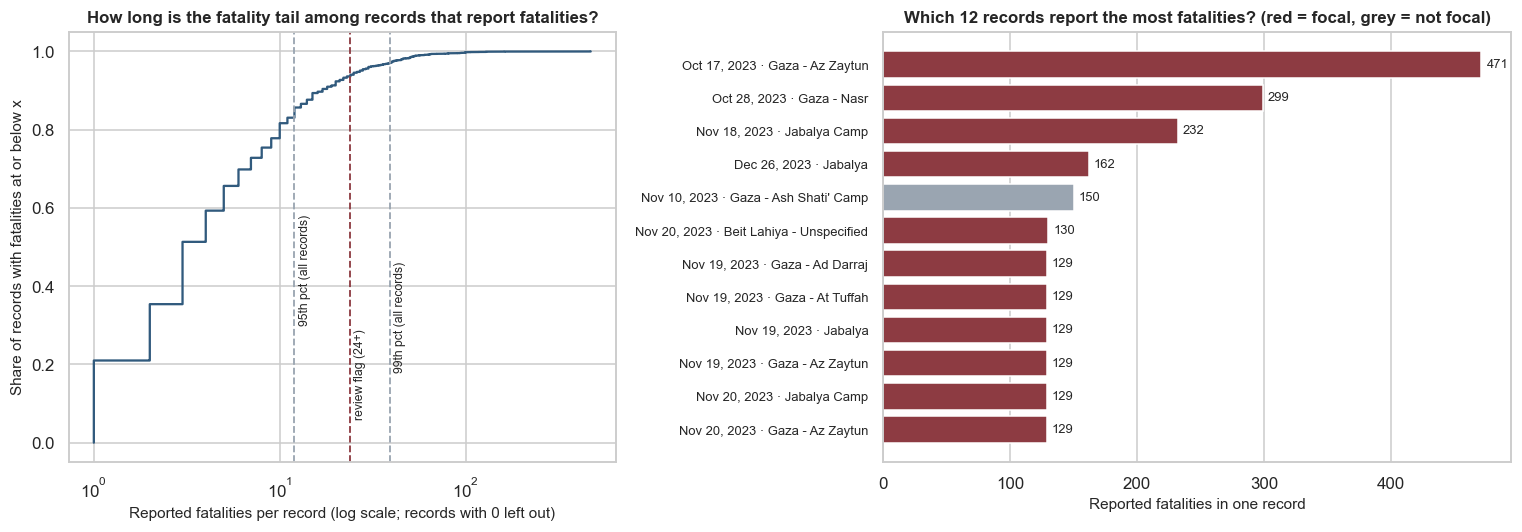

In [8]:
pos = np.sort(f[f > 0].to_numpy())
ecdf = np.arange(1, len(pos) + 1) / len(pos)
top = master.nlargest(12, "fatalities").iloc[::-1]
labels = [f"{d:%b %d, %Y} · {loc}" for d, loc in zip(top.event_date, top.location)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
ax.step(pos, ecdf, where="post", color=C_OTHER)
ax.set_xscale("log")
for xv, lab in [(f.quantile(.95), "95th pct (all records)"), (f.quantile(.99), "99th pct (all records)"), (thr, f"review flag ({thr}+)")]:
    ax.axvline(xv, color=C_FOCAL if "flag" in lab else C_GREY, ls="--", lw=1.2)
    ax.text(xv * 1.05, 0.06 if "flag" in lab else (0.18 if "99" in lab else 0.30), lab, rotation=90, fontsize=8, va="bottom")
ax.set_xlabel("Reported fatalities per record (log scale; records with 0 left out)")
ax.set_ylabel("Share of records with fatalities at or below x")
ax.set_title("How long is the fatality tail among records that report fatalities?")
ax.grid(axis="x", visible=True)

ax = axes[1]
ax.barh(range(len(top)), top.fatalities, color=[C_FOCAL if v else C_GREY for v in top.focal_event])
ax.set_yticks(range(len(top))); ax.set_yticklabels(labels, fontsize=8.5)
for y, v in enumerate(top.fatalities):
    ax.text(v + 4, y, f"{v}", va="center", fontsize=8.5)
ax.set_xlabel("Reported fatalities in one record")
ax.set_title("Which 12 records report the most fatalities? (red = focal, grey = not focal)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

**Interpretation.** Two thirds of records report zero fatalities (66.1%), the 95th percentile is 12 and the 99th is 39, yet the maximum is 471 (Gaza - Az Zaytun, Oct 17, 2023); the 576 flagged records are only 2.2% of records but hold 37.6% of all reported fatalities (BQ4). The three largest records all fall in Oct to Nov 2023, and 422 of the 576 flagged records are focal, with another 97 being Battles. These records dominate any sum or mean of fatalities, so medians and shares are safer summaries (as Task 2 already does); a very large total may be one event or an aggregated report, which only the event notes can settle.

### Chart 3 — When are the high-fatality records concentrated?

,Focal,Not focal,Share of that quarter's records flagged
quarter,,,
2023Q4,235,46,0.077
2024Q1,81,14,0.026
2024Q2,26,21,0.015
2024Q3,6,31,0.012
2024Q4,21,30,0.017
2025Q1,3,2,0.004
2025Q2,23,8,0.009
2025Q3,27,2,0.009


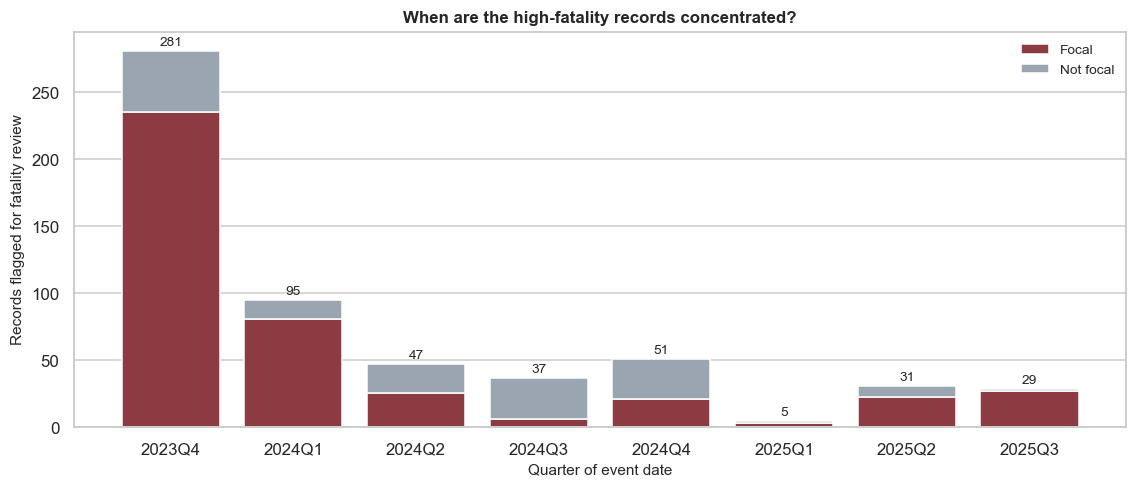

In [9]:
q = flag.assign(quarter=flag.event_date.dt.to_period("Q").astype(str))
qt = pd.crosstab(q.quarter, q.focal_event).reindex(columns=[True, False], fill_value=0)
qt.columns = ["Focal", "Not focal"]
all_q = master.assign(quarter=master.event_date.dt.to_period("Q").astype(str))
qt = qt.reindex(sorted(all_q.quarter.unique()), fill_value=0)
qt = qt.loc[qt.index >= "2023Q4"]
qt["Share of that quarter's records flagged"] = qt.sum(axis=1) / all_q.groupby("quarter").size().reindex(qt.index)
display(qt.round({"Share of that quarter's records flagged": 3}))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.bar(qt.index, qt["Focal"], color=C_FOCAL, label="Focal")
ax.bar(qt.index, qt["Not focal"], bottom=qt["Focal"], color=C_GREY, label="Not focal")
for x, (_, r) in enumerate(qt.iterrows()):
    ax.text(x, r["Focal"] + r["Not focal"] + 4, f"{int(r['Focal'] + r['Not focal'])}", ha="center", fontsize=9)
ax.set_xlabel("Quarter of event date"); ax.set_ylabel("Records flagged for fatality review")
ax.set_title("When are the high-fatality records concentrated?")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretation.** Q4 2023 holds 281 of the 576 flagged records (235 focal, 46 not focal) and 7.7% of that quarter's records are flagged, against 2.6% in Q1 2024 and 1.7% or less in every later quarter (BQ4). The extreme-total problem is therefore mostly a feature of the first three months, so including or dropping flagged records changes early-period results far more than later ones. This is a count threshold, not a verification, and a quiet quarter does not mean low harm; reporting coverage can differ across periods.

### 4.2 Unusual weeks

**Question.** Which Gaza-wide weeks have counts far from the typical week? Two rules are compared on the 103 complete weeks: a **whole-period** robust z-score (median 98 and MAD 17 for focal events) and the **trailing 8-week** rule planned for Phase 4. The first 8 weeks have no trailing score, and the incomplete final week is shown but not scored.

*Source table: `acled_gaza_week.csv`. Unit: one Gaza week.*

In [10]:
gwc = gaza_week[gaza_week.complete_week].sort_values("week_start").set_index("week_start").copy()
partial = gaza_week[~gaza_week.complete_week]
for c in ["focal_events", "political_events", "focal_share"]:
    gwc[f"rz_{c}"] = robust_z(gwc[c])                    # against the whole period
    gwc[f"tz_{c}"] = trailing_robust_z(gwc[c], window=8)  # against the previous 8 weeks only

med = {c: gwc[c].median() for c in ["focal_events", "political_events", "focal_share"]}
mad = {c: (gwc[c] - med[c]).abs().median() for c in med}
print("Median / MAD of weekly values (complete weeks):",
      {c: (round(med[c], 3), round(mad[c], 3)) for c in med})
print(f"|modified z| > {Z_CUT}:  focal_events {int((gwc.rz_focal_events.abs() > Z_CUT).sum())} weeks | "
      f"political_events {int((gwc.rz_political_events.abs() > Z_CUT).sum())} | focal_share {int((gwc.rz_focal_share.abs() > Z_CUT).sum())}")
print(f"Trailing 8-week rule: focal_events {int((gwc.tz_focal_events.abs() > Z_CUT).sum())} weeks | "
      f"political_events {int((gwc.tz_political_events.abs() > Z_CUT).sum())} | focal_share {int((gwc.tz_focal_share.abs() > Z_CUT).sum())}")

flagged = gwc[(gwc[["rz_focal_events", "rz_political_events", "tz_focal_events", "tz_political_events"]].abs() > Z_CUT).any(axis=1)]
display(flagged[["focal_events", "political_events", "focal_share", "rz_focal_events", "rz_political_events",
                 "tz_focal_events", "tz_political_events"]].round(2))

Median / MAD of weekly values (complete weeks): {'focal_events': (98.0, 17.0), 'political_events': (214.0, 33.0), 'focal_share': (0.472, 0.097)}
|modified z| > 3.5:  focal_events 3 weeks | political_events 5 | focal_share 0
Trailing 8-week rule: focal_events 13 weeks | political_events 17 | focal_share 0


,focal_events,political_events,focal_share,rz_focal_events,rz_political_events,tz_focal_events,tz_political_events
week_start,,,,,,,
2023-10-21,203,289,0.70,4.17,1.53,NaN,NaN
2023-10-28,254,360,0.71,6.19,2.98,NaN,NaN
2023-11-04,233,365,0.64,5.36,3.09,NaN,NaN
2024-02-10,103,203,0.51,0.20,-0.22,0.39,-8.91
2024-02-24,99,254,0.39,0.04,0.82,-0.12,-4.41
2024-03-30,67,219,0.31,-1.23,0.10,-4.32,-2.21
2024-06-08,70,201,0.35,-1.11,-0.27,-3.66,-2.30
2024-06-15,69,190,0.36,-1.15,-0.49,-3.85,-2.85
2024-10-05,100,237,0.42,0.08,0.47,1.12,4.64


### Chart 4 — Which weeks are unusual for focal events and for political-violence records?

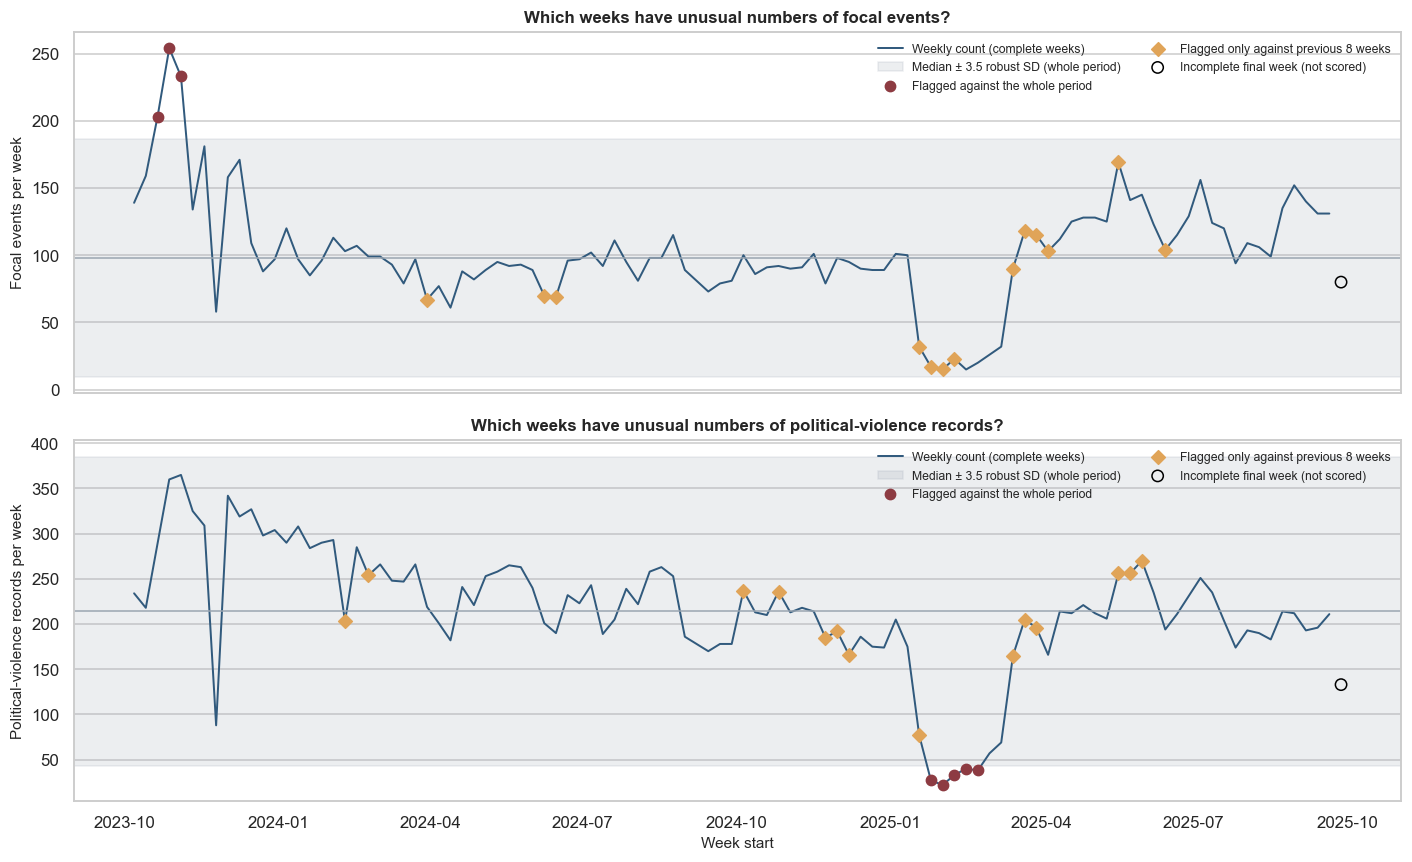

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, col, title, ylab in [
    (axes[0], "focal_events", "Which weeks have unusual numbers of focal events?", "Focal events per week"),
    (axes[1], "political_events", "Which weeks have unusual numbers of political-violence records?", "Political-violence records per week")]:
    s = gwc[col]
    ax.plot(s.index, s, color=C_OTHER, lw=1.3, label="Weekly count (complete weeks)")
    band = 1.4826 * mad[col] * Z_CUT
    ax.axhspan(med[col] - band, med[col] + band, color=C_GREY, alpha=0.18, label=f"Median ± {Z_CUT} robust SD (whole period)")
    ax.axhline(med[col], color=C_GREY, lw=1)
    g_flag = gwc[gwc[f"rz_{col}"].abs() > Z_CUT]
    t_flag = gwc[(gwc[f"tz_{col}"].abs() > Z_CUT) & ~(gwc[f"rz_{col}"].abs() > Z_CUT)]
    ax.scatter(g_flag.index, g_flag[col], color=C_FOCAL, s=45, zorder=3, label="Flagged against the whole period")
    ax.scatter(t_flag.index, t_flag[col], color=C_WARN, marker="D", s=40, zorder=3, label="Flagged only against previous 8 weeks")
    ax.scatter(partial.week_start, partial[col], facecolors="none", edgecolors="black", s=55, zorder=4, label="Incomplete final week (not scored)")
    ax.set_title(title); ax.set_ylabel(ylab)
    ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper right")
axes[1].set_xlabel("Week start")
plt.tight_layout(); plt.show()

**Interpretation.** Against the whole period only three focal-event weeks stand out, all at the very start (Oct 21, Oct 28 with the peak of 254, and Nov 4, 2023), and only five political-violence weeks stand out, all low (Jan 25 to Feb 22, 2025, with 22 to 40 records); no week has an unusual focal *share* (30% to 73%) (BQ4). The trailing rule flags 13 focal-event weeks, but most of the highs (Mar 15 to Apr 5, 2025 and May 17, 2025) are the recovery after the Jan to Feb 2025 collapse, with 90 to 169 events against a long-run median of 98, so a short baseline scores a return to normal as a spike. The files contain no source for the Jan to Feb 2025 fall, so we describe it and do not explain it; the dip in the week of Nov 25, 2023 (58 focal events) is not flagged by either rule, and the first 8 weeks have no trailing score at all.

### District-week check with the same trailing rule

In [12]:
# Same trailing 8-week rule, applied inside each district (complete weeks only).
dwc = district_week[district_week.complete_week].sort_values(["admin2", "week_start"]).copy()
dwc["tz_focal"] = dwc.groupby("admin2").focal_events.transform(lambda s: trailing_robust_z(s, window=8))
elig = dwc.tz_focal.notna()
dist_flags = (dwc[elig].assign(high=lambda d: d.tz_focal > Z_CUT, low=lambda d: d.tz_focal < -Z_CUT)
              .groupby("admin2").agg(scored_weeks=("tz_focal", "size"), high_weeks=("high", "sum"), low_weeks=("low", "sum")))
dist_flags["flagged share"] = (dist_flags.high_weeks + dist_flags.low_weeks) / dist_flags.scored_weeks
display(dist_flags.round({"flagged share": 3}))
print("All districts together:", int((dist_flags.high_weeks + dist_flags.low_weeks).sum()), "flagged of",
      int(dist_flags.scored_weeks.sum()), "scored district-weeks =",
      f"{(dist_flags.high_weeks + dist_flags.low_weeks).sum() / dist_flags.scored_weeks.sum():.1%}")
print("Highest-scoring district-weeks (upward):")
display(dwc.nlargest(6, "tz_focal")[["admin2", "week_start", "focal_events", "political_events", "tz_focal"]].round({"tz_focal": 2}))

,scored_weeks,high_weeks,low_weeks,flagged share
admin2,,,,
Deir El Balah,95,6,2,0.084
Gaza City,95,9,4,0.137
Khan Yunis,95,7,0,0.074
North Gaza,95,11,3,0.147
Rafah,95,5,3,0.084


All districts together: 50 flagged of 475 scored district-weeks = 10.5%
Highest-scoring district-weeks (upward):


,admin2,week_start,focal_events,political_events,tz_focal
285,Khan Yunis,2025-03-29,48,69,11.47
76,Deir El Balah,2025-03-22,18,35,10.79
249,Khan Yunis,2024-07-20,41,67,10.79
180,Gaza City,2025-03-22,28,48,10.57
77,Deir El Balah,2025-03-29,17,35,10.12
387,North Gaza,2025-03-15,16,22,10.12


**Interpretation.** In 475 scored district-weeks, 50 (10.5%) are flagged, and the share is highest in North Gaza (14.7%) and Gaza City (13.7%) and lowest in Khan Yunis (7.4%) (BQ4). The six highest upward scores come from March 2025 and one week of July 2024 (Khan Yunis, Jul 20, 41 focal events), which repeats the recovery effect seen above. Flagged weeks are about one in ten, so a weekly anomaly detector faces an imbalanced target of its own, and small districts such as North Gaza have low weekly counts and give noisy scores.

### 4.3 Is the data itself consistent?

In [13]:
lat_ok = master.latitude.between(31.2, 31.6) & master.longitude.between(34.2, 34.6)
dq = pd.DataFrame([
    ("Duplicate event IDs in the master", int(master.duplicated("event_id_cnty").sum()), "None: no event is counted twice."),
    ("Missing coordinates in the master", int(master[["latitude", "longitude"]].isna().any(axis=1).sum()), "None missing."),
    ("Coordinates outside a rough Gaza box (lat 31.2-31.6, lon 34.2-34.6)", int((~lat_ok).sum()), "All inside: no impossible locations."),
    ("Events with no district (kept in Gaza-wide totals)", int(master.admin2.isna().sum()), "Left out of district tables only."),
    ("Coast-coded events (kept in Gaza-wide totals)", int(master.coastal_location.sum()), "Left out of the land spatial table only."),
    ("Zero-event weeks in the Gaza-week table", int((gaza_week.recorded_events == 0).sum()), "None: weekly activity never stops in the record."),
    ("Incomplete final week", f"{partial.week_start.dt.date.iloc[0]} to {partial.week_end.dt.date.iloc[0]}", "Marked and left out of scoring; the export ends Sep 30, 2025."),
    ("Records with 0 reported fatalities", f"{(master.fatalities == 0).mean():.1%}", "A zero may mean no figure was recorded, not that nobody was hurt."),
    ("Records with time precision other than 1", f"{(master.time_precision != 1).mean():.1%}", "Date is not exact for these; weekly counts can shift by a week."),
    ("Land focal incidents", len(incidents), ""),
    ("Distinct coordinate pairs among them", len(incidents[["latitude", "longitude"]].drop_duplicates()), "Many incidents share one coordinate: they stand for named places, not exact points."),
], columns=["Check", "Result", "Reading"])
display(dq)

,Check,Result,Reading
0,Duplicate event IDs in the master,0,None: no event is counted twice.
1,Missing coordinates in the master,0,None missing.
2,Coordinates outside a rough Gaza box (lat 31.2...,0,All inside: no impossible locations.
3,Events with no district (kept in Gaza-wide tot...,4,Left out of district tables only.
4,Coast-coded events (kept in Gaza-wide totals),701,Left out of the land spatial table only.
5,Zero-event weeks in the Gaza-week table,0,None: weekly activity never stops in the record.
6,Incomplete final week,2025-09-27 to 2025-10-03,Marked and left out of scoring; the export end...
7,Records with 0 reported fatalities,66.1%,"A zero may mean no figure was recorded, not th..."
8,Records with time precision other than 1,0.8%,Date is not exact for these; weekly counts can...
9,Land focal incidents,10583,


**Interpretation.** The checks find no duplicate IDs, no missing coordinates and no coordinates outside the Gaza area, and every Gaza week has recorded activity (BQ5). The cautions are about meaning: 66.1% of records report zero fatalities, 701 events are coast-coded and left out of the land map only, and the 10,583 land focal incidents sit on just **101 distinct coordinates**, so a coordinate stands for a named place and not an exact point. Only 0.8% of records have a time precision other than 1, so weekly counts are stable against date uncertainty.

## 5. Trends

**Question.** Over the two years from Oct 7, 2023, is there a lasting direction in weekly focal events, in political-violence records or in the focal share? Weekly values are summed to months (a week belongs to the month it starts in; complete weeks only) so the long-run shape is easier to see than in the weekly charts of Task 3. A Spearman rank correlation with week number gives a rough direction; the p-values are only a guide because neighbouring weeks are not independent.

*Source table: `acled_gaza_week.csv`. Unit: one Gaza week, summed to months.*

In [14]:
wk = gwc.reset_index()
wk["month"] = wk.week_start.dt.to_period("M")
mo = wk.groupby("month").agg(focal=("focal_events", "sum"), political=("political_events", "sum"), weeks=("focal_events", "size"))
mo["share"] = mo.focal / mo.political
mo.index = mo.index.astype(str)
display(mo.T.round(3))

wk["quarter"] = wk.week_start.dt.to_period("Q").astype(str)
qtr = wk.groupby("quarter").agg(weeks=("focal_events", "size"), mean_focal_per_week=("focal_events", "mean"),
                                mean_political_per_week=("political_events", "mean"), pooled_share=("focal_events", "sum"))
qtr["pooled_share"] = qtr.pooled_share / wk.groupby("quarter").political_events.sum()
display(qtr.round({"mean_focal_per_week": 1, "mean_political_per_week": 1, "pooled_share": 3}))

# Rank trend against time (exploratory: weeks are serially dependent, so the p-values are only a rough guide)
t = np.arange(len(gwc))
trend = []
for c in ["focal_events", "political_events", "focal_share"]:
    rho, p = spearmanr(t, gwc[c])
    half = len(gwc) // 2
    trend.append({"Weekly measure": c, "Spearman rho vs week number": rho, "p (rough)": p,
                  "Median, first half": gwc[c].iloc[:half].median(), "Median, second half": gwc[c].iloc[half:].median()})
display(pd.DataFrame(trend).set_index("Weekly measure").round(3))

month,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,...,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09
focal,755.000,606.000,623.000,398.00,422.000,435.000,308.000,369.000,421.000,400.000,...,363.000,250.000,73.000,381.000,468.000,708.00,471.000,494.000,601.000,402.00
political,1101.000,1087.000,1590.000,1172.00,1035.000,1246.000,845.000,1039.000,1086.000,876.000,...,701.000,484.000,133.000,692.000,813.000,1200.00,871.000,864.000,992.000,600.00
weeks,4.000,4.000,5.000,4.00,4.000,5.000,4.000,4.000,5.000,4.000,...,4.000,4.000,4.000,5.000,4.000,5.00,4.000,4.000,5.000,3.00
share,0.686,0.557,0.392,0.34,0.408,0.349,0.364,0.355,0.388,0.457,...,0.518,0.517,0.549,0.551,0.576,0.59,0.541,0.572,0.606,0.67


,weeks,mean_focal_per_week,mean_political_per_week,pooled_share
quarter,,,,
2023Q4,13,152.6,290.6,0.525
2024Q1,13,96.5,265.6,0.363
2024Q2,13,84.5,228.5,0.370
2024Q3,13,91.9,212.5,0.433
2024Q4,13,91.6,201.5,0.455
2025Q1,13,54.2,100.7,0.538
2025Q2,13,126.7,221.8,0.571
2025Q3,12,124.8,204.7,0.610


,Spearman rho vs week number,p (rough),"Median, first half","Median, second half"
Weekly measure,,,,
focal_events,0.104,0.295,96.000,101.000
political_events,-0.550,0.000,253.000,200.000
focal_share,0.514,0.000,0.383,0.543


### Chart 5 — Is there a lasting trend in monthly focal events and in their share?

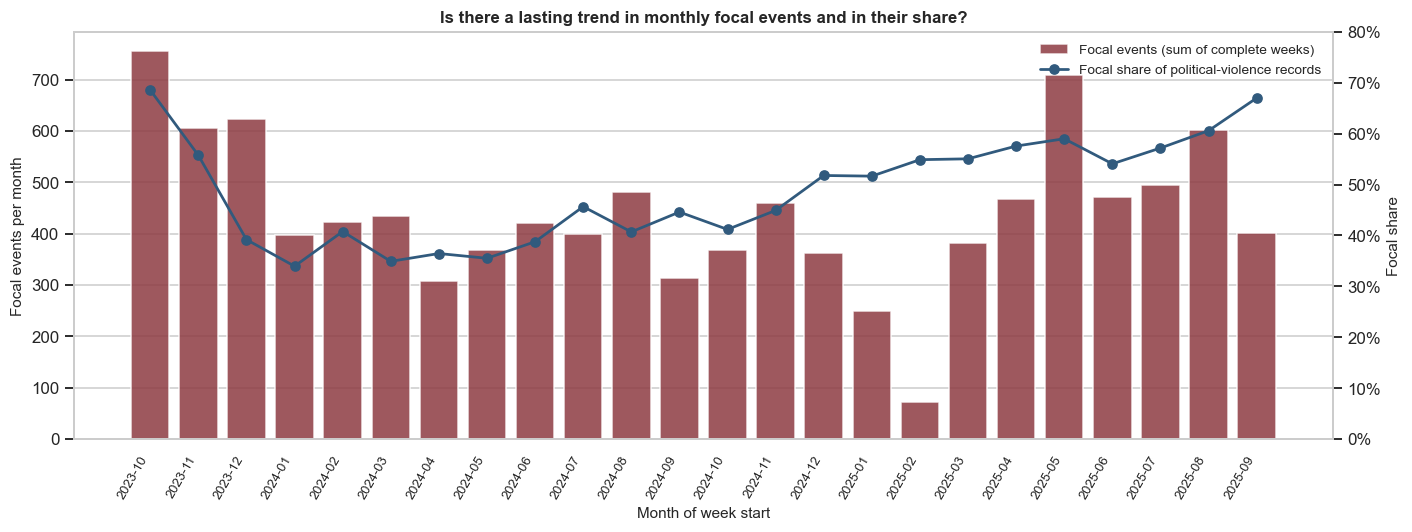

In [15]:
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(mo))
ax.bar(x, mo.focal, color=C_FOCAL, alpha=0.85, label="Focal events (sum of complete weeks)")
ax.set_xticks(x); ax.set_xticklabels(mo.index, rotation=60, ha="right", fontsize=8.5)
ax.set_ylabel("Focal events per month"); ax.set_xlabel("Month of week start")
ax.set_title("Is there a lasting trend in monthly focal events and in their share?")
ax2 = ax.twinx()
ax2.plot(x, mo["share"], color=C_OTHER, marker="o", lw=1.8, label="Focal share of political-violence records")
ax2.set_ylabel("Focal share"); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax2.set_ylim(0, 0.8)
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

**Interpretation.** Focal events show no lasting direction (Spearman 0.10, median 96 per week in the first half and 101 in the second), but political-violence records fall (rho -0.55, median 253 to 200) and the focal share rises (rho 0.51, median 38.3% to 54.3%), from a trough of 34.0% in Jan 2024 to 67.0% in Sep 2025 (BQ1, BQ4). In other words the share rises mainly because the non-focal part of political violence falls while focal counts hold, and the monthly counts swing from 755 (Oct 2023) down to 73 (Feb 2025) and back to 708 (May 2025), so the series is a set of level shifts and not a straight line. The first and last months cover only 4 and 3 weeks, and the rank-correlation p-values ignore serial dependence.

## 6. Seasonality and persistence

**Question.** Do the same calendar months or weekdays repeat, and does a week resemble the weeks before it? The data cover about two years, so each calendar month appears at most twice (Oct to Dec in 2023 and 2024, Jan to Sep in 2024 and 2025) and a 52-week cycle cannot be tested at all. We therefore compare the two years month by month, look at weekdays, and use the autocorrelation function (ACF) to check persistence.

*Source tables: `acled_gaza_week.csv` (months, ACF) and `acled_events_clean.csv` (weekdays, focal events from Oct 7).*

### Chart 6 — Do the same calendar months and weekdays repeat?

year,2023,2024,2025
mon,,,
1,NaN,99.5,62.5
2,NaN,105.5,18.2
3,NaN,87.0,76.2
4,NaN,77.0,117.0
5,NaN,92.2,141.6
6,NaN,84.2,117.8
7,NaN,100.0,123.5
8,NaN,96.2,120.2
9,NaN,78.5,134.0


Months present in both 2024 and 2025: 9 (Jan-Sep). Spearman rho between the two years' monthly means = -0.30
Focal events by weekday: {'Mon': 1474, 'Tue': 1597, 'Wed': 1571, 'Thu': 1521, 'Fri': 1485, 'Sat': 1559, 'Sun': 1444} | highest / lowest = 1.11


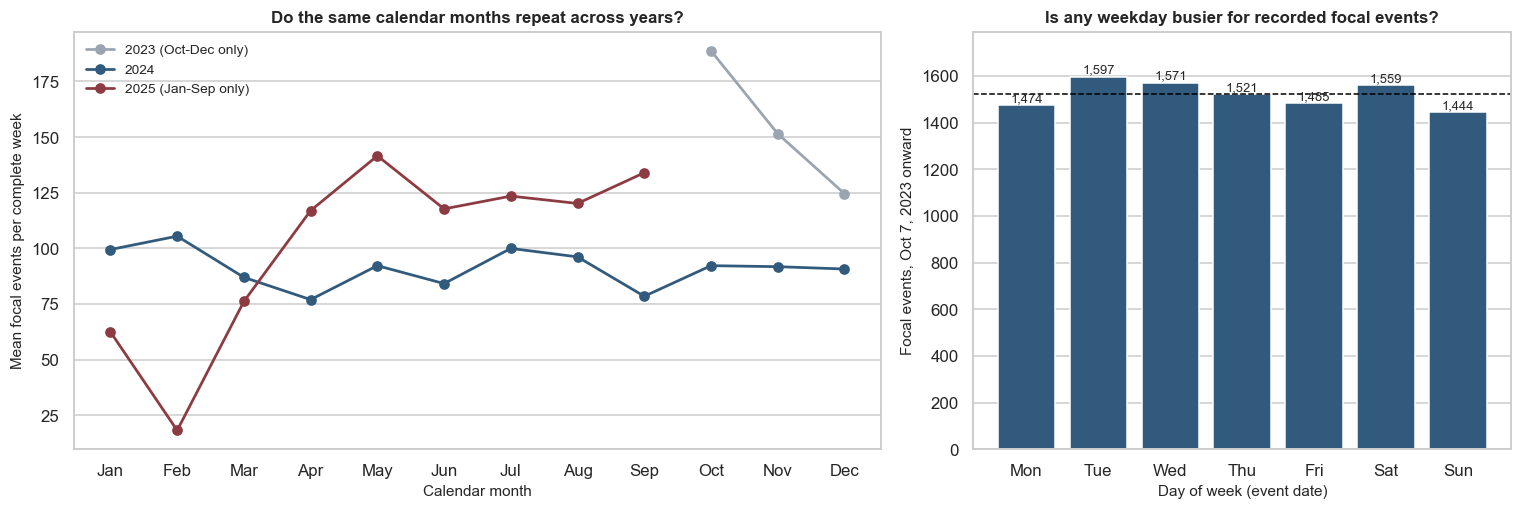

In [16]:
wk["year"], wk["mon"] = wk.week_start.dt.year, wk.week_start.dt.month
moy = wk.groupby(["year", "mon"]).focal_events.mean().unstack(0)
display(moy.round(1))
both = moy[[2024, 2025]].dropna()
rho_yy, _ = spearmanr(both[2024], both[2025])
print(f"Months present in both 2024 and 2025: {len(both)} (Jan-Sep). Spearman rho between the two years' monthly means = {rho_yy:.2f}")

post_focal = master[(master.focal_event) & (master.period == AFTER)]
dow = post_focal.event_date.dt.dayofweek.value_counts().sort_index()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Focal events by weekday:", dow.to_dict(), f"| highest / lowest = {dow.max() / dow.min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for yr, col in zip([2023, 2024, 2025], [C_GREY, C_OTHER, C_FOCAL]):
    s = moy[yr].dropna()
    ax.plot(s.index, s.values, marker="o", color=col, lw=1.8, label=str(yr) + (" (Oct-Dec only)" if yr == 2023 else " (Jan-Sep only)" if yr == 2025 else ""))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlabel("Calendar month"); ax.set_ylabel("Mean focal events per complete week")
ax.set_title("Do the same calendar months repeat across years?")
ax.legend(frameon=False)
ax = axes[1]
ax.bar(dow.index, dow.values, color=C_OTHER)
ax.axhline(dow.mean(), color="black", ls="--", lw=1)
for i, v in enumerate(dow.values):
    ax.text(i, v + 15, f"{v:,}", ha="center", fontsize=8.5)
ax.set_ylim(0, dow.max() * 1.12)
ax.set_xlabel("Day of week (event date)"); ax.set_ylabel("Focal events, Oct 7, 2023 onward")
ax.set_title("Is any weekday busier for recorded focal events?")
plt.tight_layout(); plt.show()

*(The cell above also prints the monthly means and weekday counts behind the chart.)*

**Interpretation.** The two years do not share a calendar shape: for the nine months present in both (Jan to Sep), the correlation between 2024 and 2025 monthly means is -0.30, February is 105.5 per week in 2024 and 18.2 in 2025, and Oct to Dec 2023 (188.8, 151.5 and 124.6) is far above the same months of 2024 (about 91) (BQ4). Weekday counts range only from 1,444 (Sunday) to 1,597 (Tuesday), a ratio of 1.11, so no day stands out. There is no evidence of seasonality here, but two years cannot rule out a longer cycle, and weekday counts also reflect when events are reported.

### Chart 7 — Does a week resemble the weeks before it?

ACF of weekly focal events, lags 1-12: [ 0.76  0.63  0.49  0.39  0.34  0.26  0.18  0.12  0.08  0.03  0.   -0.04]
ACF of week-to-week changes, lags 1-12: [-0.26  0.02 -0.13 -0.08  0.11 -0.03  0.02 -0.09  0.02 -0.04  0.04 -0.11]
Approximate 95% band: ±0.19  (n = 103 weeks).
A 52-week cycle cannot be checked: the table spans only 104 weeks (about two years).


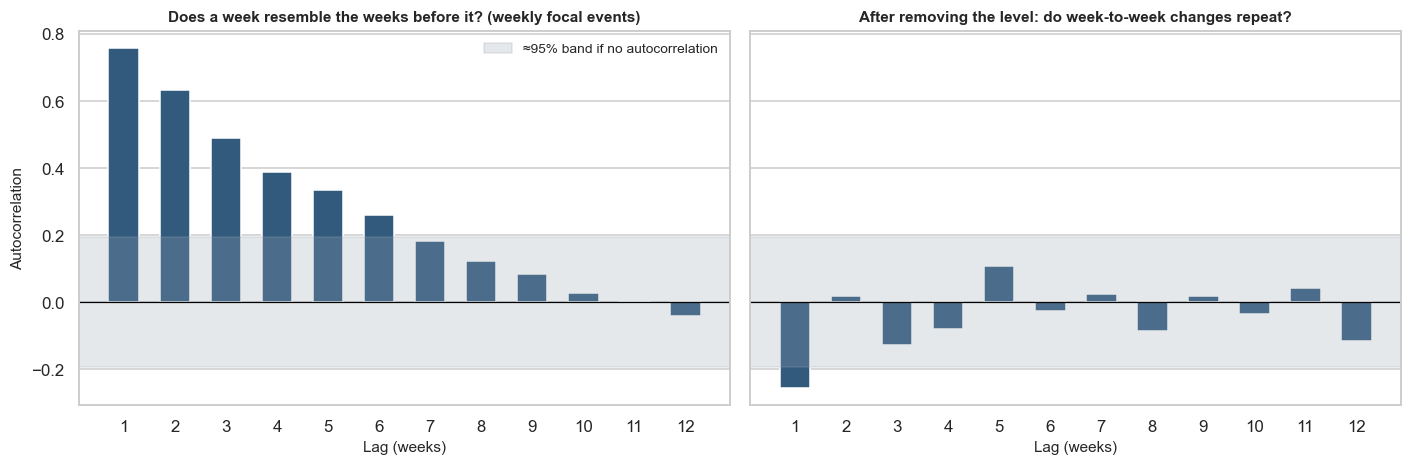

In [17]:
def acf(x, nlags):
    x = np.asarray(x, float); x = x - x.mean()
    return np.array([(x[:-k] * x[k:]).sum() / (x * x).sum() for k in range(1, nlags + 1)])

series = gwc.focal_events.to_numpy(float)
lags = np.arange(1, 13)
acf_level, acf_diff = acf(series, 12), acf(np.diff(series), 12)
band = 1.96 / np.sqrt(len(series))
print("ACF of weekly focal events, lags 1-12:", np.round(acf_level, 2))
print("ACF of week-to-week changes, lags 1-12:", np.round(acf_diff, 2))
print(f"Approximate 95% band: ±{band:.2f}  (n = {len(series)} weeks).")
print("A 52-week cycle cannot be checked: the table spans only", len(gaza_week), "weeks (about two years).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, vals, title in [(axes[0], acf_level, "Does a week resemble the weeks before it? (weekly focal events)"),
                        (axes[1], acf_diff, "After removing the level: do week-to-week changes repeat?")]:
    ax.bar(lags, vals, color=C_OTHER, width=0.6)
    ax.axhline(0, color="black", lw=0.8)
    ax.axhspan(-band, band, color=C_GREY, alpha=0.25, label="≈95% band if no autocorrelation")
    ax.set_xlabel("Lag (weeks)"); ax.set_title(title, fontsize=10)
    ax.set_xticks(lags)
axes[0].set_ylabel("Autocorrelation"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation.** Weekly focal events are strongly persistent: the autocorrelation is 0.76 at lag 1 and decays slowly (0.63, 0.49, 0.39, 0.34, 0.26) until it falls inside the ±0.19 band at lag 7, while the week-to-week *changes* are essentially uncorrelated (only lag 1, -0.26, sits just outside the band) (BQ4). A slow decay with no peak at lag 4 or 8 points to level shifts (the regimes in Section 7) and not to a repeating cycle, which supports using the previous week and the previous four weeks as history features in Phase 4. Level shifts inflate the autocorrelation of any non-stationary series, so these values describe persistence, not predictability.

## 7. Segments and clustering

Three groupings: districts (by volume and burstiness), weeks (by what kind of week they were) and places (by where incidents are recorded). The last one also previews the DBSCAN settings Phase 4 will use. These are **descriptive groupings**, not validated models, and a cluster is a recorded concentration, not an exact attack point.

### 7.1 District segments

**Question.** Which districts carry most focal events, is that split stable, and which districts are bursty? Only the 5 known districts are used (the 4 events with no district are excluded, 3 of them focal), and the incomplete final week is dropped. Burstiness is the standard deviation divided by the mean of weekly counts.

*Source table: `acled_district_week.csv`. Unit: one district-week.*

### Chart 8 — Which districts carry the focal events, and how steady are they?

,total,median,mean,sd,peak,cv,share_of_known_district_focal,weeks_with_zero
admin2,,,,,,,,
Gaza City,3411,30.0,33.1,19.0,102,0.57,0.323,0
Khan Yunis,2278,22.0,22.1,14.4,64,0.65,0.216,0
Deir El Balah,2257,22.0,21.9,8.9,44,0.40,0.214,0
North Gaza,1325,9.0,12.9,10.7,61,0.83,0.125,6
Rafah,1297,10.0,12.6,6.4,31,0.50,0.123,0


Range of each district's 4-week share of known-district focal events:


,min,max
admin2,,
Gaza City,0.151,0.558
Khan Yunis,0.065,0.402
Deir El Balah,0.084,0.332
North Gaza,0.012,0.291
Rafah,0.024,0.470


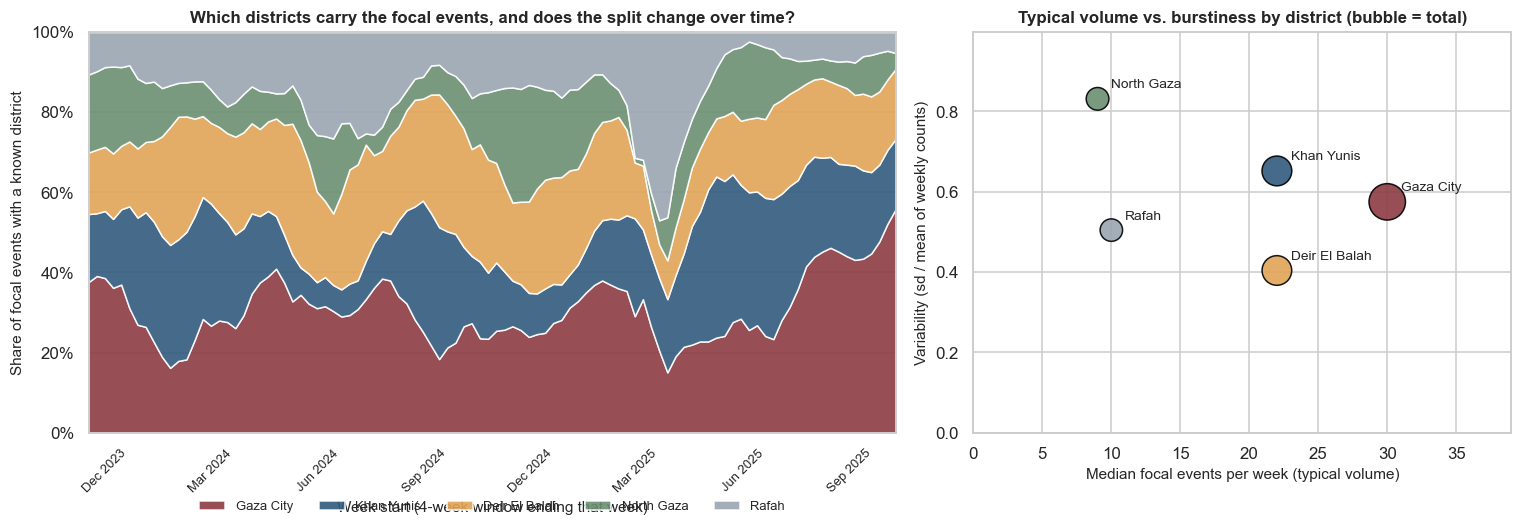

In [18]:
pivot = dwc.pivot(index="week_start", columns="admin2", values="focal_events")
roll = pivot.rolling(4).sum()
share4 = roll.div(roll.sum(axis=1), axis=0).dropna()
order = pivot.sum().sort_values(ascending=False).index.tolist()

prof = dwc.groupby("admin2").focal_events.agg(total="sum", median="median", mean="mean", sd="std", peak="max")
prof["cv"] = prof.sd / prof["mean"]
prof["share_of_known_district_focal"] = prof.total / prof.total.sum()
prof["weeks_with_zero"] = dwc.groupby("admin2").focal_events.apply(lambda s: int((s == 0).sum()))
prof = prof.loc[order]
display(prof.round({"mean": 1, "sd": 1, "cv": 2, "share_of_known_district_focal": 3}))
print("Range of each district's 4-week share of known-district focal events:")
display(pd.DataFrame({"min": share4.min(), "max": share4.max()}).loc[order].round(3))

dist_colors = dict(zip(order, ["#8D3B42", "#315A7D", "#E0A458", "#6B8F71", "#9AA5B1"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.stackplot(share4.index, [share4[d] for d in order], labels=order, colors=[dist_colors[d] for d in order], alpha=0.9)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(share4.index.min(), share4.index.max())
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8.5)
ax.set_xlabel("Week start (4-week window ending that week)"); ax.set_ylabel("Share of focal events with a known district")
ax.set_title("Which districts carry the focal events, and does the split change over time?")
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=8.5)
ax = axes[1]
ax.scatter(prof["median"], prof["cv"], s=prof.total / 6, color=[dist_colors[d] for d in prof.index], alpha=0.9, edgecolor="black")
for d, r in prof.iterrows():
    ax.annotate(d, (r["median"], r["cv"]), textcoords="offset points", xytext=(9, 7), fontsize=9)
ax.set_xlim(0, prof["median"].max() * 1.3); ax.set_ylim(0, prof.cv.max() * 1.2)
ax.set_xlabel("Median focal events per week (typical volume)"); ax.set_ylabel("Variability (sd / mean of weekly counts)")
ax.set_title("Typical volume vs. burstiness by district (bubble = total)")
ax.grid(axis="x", visible=True)
plt.tight_layout(); plt.show()

**Interpretation.** Gaza City carries the most focal events (3,411, 32.3% of those with a known district; median 30 per week and a peak of 102), followed by Khan Yunis (21.6%) and Deir El Balah (21.4%), while North Gaza (12.5%) and Rafah (12.3%) are each about 40% of Gaza City's total (BQ4). North Gaza is the most bursty (variability 0.83, with 6 complete weeks of zero focal events) and Deir El Balah the steadiest (0.40), and a district's 4-week share swings widely, for example Gaza City from 15.1% to 55.8% and Rafah from 2.4% to 47.0%. Districts therefore need their own baselines and not one Gaza-wide threshold; these shares are of events with a known district, and a district count can rise because a place is better documented.

### 7.2 Segments of weeks

**Question.** Do weeks fall into a few kinds? We cluster the 103 complete weeks with k-means on three standardised measures (log of focal events, log of political-violence records, focal share). The silhouette score helps choose *k* and is only a rough guide with 103 points.

In [19]:
feat = gwc[["focal_events", "political_events", "focal_share"]].copy()
feat["focal_events"], feat["political_events"] = np.log1p(feat.focal_events), np.log1p(feat.political_events)
Xs = StandardScaler().fit_transform(feat)

sil = []
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    sil.append({"k": k, "silhouette": silhouette_score(Xs, km.labels_), "smallest cluster (weeks)": int(np.bincount(km.labels_).min())})
display(pd.DataFrame(sil).set_index("k").round(3))

,silhouette,smallest cluster (weeks)
k,,
2,0.671,9
3,0.508,8
4,0.432,8
5,0.430,3


`k = 2` has the best silhouette (0.67) but only separates 9 low weeks from everything else. We use **k = 3**, which keeps those low weeks as their own group and also splits the rest by focal share (silhouette 0.51, a moderate structure); the choice is for description, not a claim that three is the true number.

### Chart 9 — What kinds of weeks occur, and when?

,weeks,first,last,median_focal,median_political,median_share
regime,,,,,,
Group A,8,2025-01-18,2025-03-08,21.5,39.0,0.495
Group B,51,2023-11-11,2024-12-14,92.0,240.0,0.383
Group C,44,2023-10-07,2025-09-20,123.5,208.5,0.574


Week starts per group:
  Group A: 2025-01-18, 2025-01-25, 2025-02-01, 2025-02-08, 2025-02-15, 2025-02-22, 2025-03-01, 2025-03-08
  Group B: 51 weeks; first 2023-11-11, last 2024-12-14
  Group C: 44 weeks; first 2023-10-07, last 2025-09-20


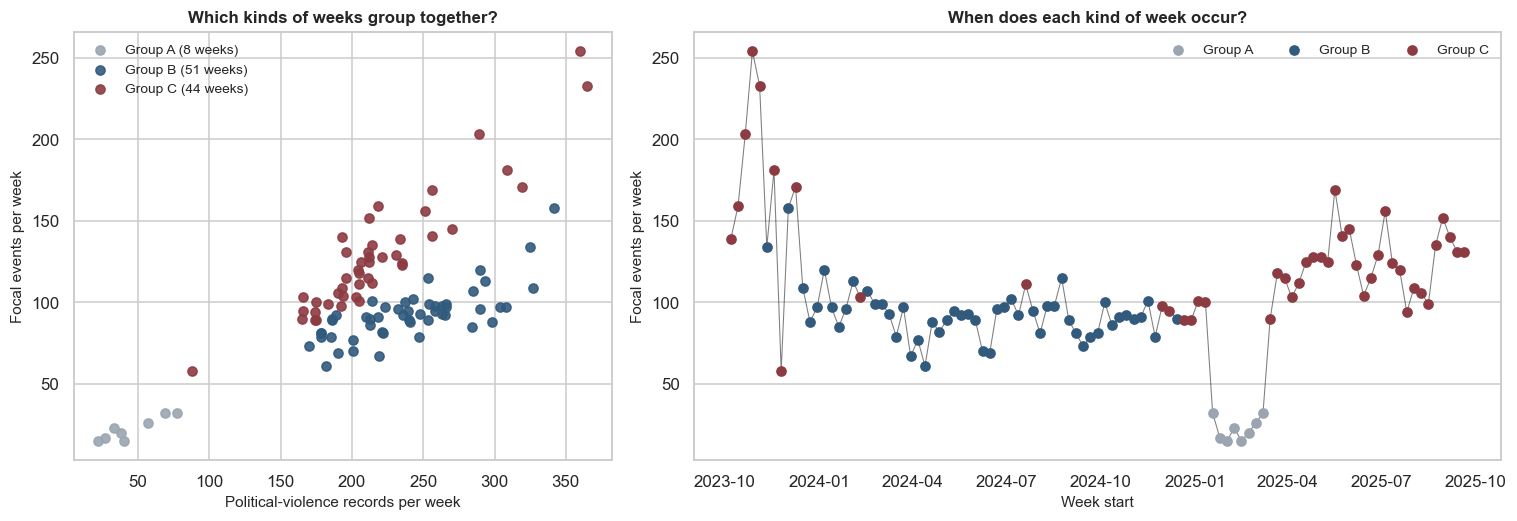

In [20]:
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs)
gwc["cluster"] = km.labels_
# Name clusters by their median focal count so the labels are stable between runs
rank = gwc.groupby("cluster").focal_events.median().sort_values().index.tolist()
names = {c: f"Group {chr(65 + i)}" for i, c in enumerate(rank)}
gwc["regime"] = gwc.cluster.map(names)
cl_prof = gwc.reset_index().groupby("regime").agg(weeks=("focal_events", "size"), first=("week_start", "min"), last=("week_start", "max"),
                                                  median_focal=("focal_events", "median"), median_political=("political_events", "median"),
                                                  median_share=("focal_share", "median"))
display(cl_prof.round({"median_focal": 1, "median_political": 1, "median_share": 3}))
print("Week starts per group:")
for g, d in gwc.groupby("regime"):
    print(f"  {g}:", ", ".join(f"{x:%Y-%m-%d}" for x in d.index) if len(d) <= 12 else f"{len(d)} weeks; first {d.index.min():%Y-%m-%d}, last {d.index.max():%Y-%m-%d}")

pal = dict(zip(sorted(names.values()), [C_GREY, C_OTHER, C_FOCAL]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
for g, d in gwc.groupby("regime"):
    ax.scatter(d.political_events, d.focal_events, color=pal[g], s=36, alpha=0.9, label=f"{g} ({len(d)} weeks)")
ax.set_xlabel("Political-violence records per week"); ax.set_ylabel("Focal events per week")
ax.set_title("Which kinds of weeks group together?"); ax.legend(frameon=False); ax.grid(axis="x", visible=True)
ax = axes[1]
ax.plot(gwc.index, gwc.focal_events, color="black", lw=0.7, alpha=0.5)
for g, d in gwc.groupby("regime"):
    ax.scatter(d.index, d.focal_events, color=pal[g], s=36, label=g, zorder=3)
ax.set_xlabel("Week start"); ax.set_ylabel("Focal events per week")
ax.set_title("When does each kind of week occur?"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

**Interpretation.** Group A is 8 weeks (Jan 18 to Mar 8, 2025) with a median of 21.5 focal events and 39 political-violence records, Group B is 51 weeks (Nov 2023 to Dec 2024) with a median of 92 focal events and a 38.3% share, and Group C is 44 weeks with a median of 123.5 focal events and a 57.4% share, made up of the first weeks after Oct 7, 2023, 6 later weeks of 2024, 2 weeks of early January 2025 and 28 weeks from Mar 15, 2025 on (BQ4). The groups follow time more than chance: an early high phase, a long 2024 plateau, the Jan to Mar 2025 gap, and a high-share 2025 phase. The B and C boundary is blurry (14 weeks of C fall before 2025), the groups are descriptive labels, and with 103 weeks a different seed or feature set could move some weeks across.

### 7.3 Where are incidents recorded?

**Question.** Where are post-Oct 7 land focal incidents concentrated, and does the picture survive when only precision-1 records are kept (BQ3, BQ5)? Many incidents share the same coordinate, so we first aggregate to distinct coordinate pairs ("sites") and then measure how unevenly incidents spread over them (Gini: 0 is even, 1 is all in one place).

*Source table: `acled_focal_incidents.csv` (land only; coast-coded events excluded). Unit: one incident, then one coordinate pair.*

In [21]:
def site_table(df):
    return (df.groupby(["latitude", "longitude"])
              .agg(events=("event_id_cnty", "size"), district=("admin2", lambda s: s.mode().iat[0]),
                   location=("location", lambda s: s.mode().iat[0]), precision1_share=("geo_precision_1", "mean"))
              .reset_index().sort_values("events", ascending=False))

sites_full = site_table(incidents)
inc_p1 = incidents[incidents.geo_precision_1]
sites_p1 = site_table(inc_p1)

def gini(v):
    v = np.sort(np.asarray(v, float)); n = len(v)
    return (2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum())

conc = pd.DataFrame({
    "Incidents": [len(incidents), len(inc_p1)],
    "Distinct coordinate pairs": [len(sites_full), len(sites_p1)],
    "Median incidents per coordinate": [sites_full.events.median(), sites_p1.events.median()],
    "Top 10 coordinates, share of incidents": [sites_full.events.head(10).sum() / len(incidents), sites_p1.events.head(10).sum() / len(inc_p1)],
    "Top 20 coordinates, share of incidents": [sites_full.events.head(20).sum() / len(incidents), sites_p1.events.head(20).sum() / len(inc_p1)],
    "Gini of incidents across coordinates": [gini(sites_full.events), gini(sites_p1.events)],
}, index=["All land focal incidents", "Precision 1 only"]).T
display(conc.round(3))
print("Share of incidents by district:")
display(incidents.admin2.value_counts(normalize=True).round(3).rename("share").to_frame())
print("Ten largest coordinates (all land focal incidents):")
display(sites_full.head(10).round({"precision1_share": 3}))

,All land focal incidents,Precision 1 only
Incidents,10583.000,7576.000
Distinct coordinate pairs,101.000,95.000
Median incidents per coordinate,54.000,33.000
"Top 10 coordinates, share of incidents",0.338,0.381
"Top 20 coordinates, share of incidents",0.565,0.625
Gini of incidents across coordinates,0.572,0.605


Share of incidents by district:


,share
admin2,
Gaza City,0.325
Khan Yunis,0.215
Deir El Balah,0.214
North Gaza,0.125
Rafah,0.122


Ten largest coordinates (all land focal incidents):


,latitude,longitude,events,district,location,precision1_share
66,31.4964,34.4522,491,Gaza City,Gaza - Az Zaytun,0.833
55,31.4486,34.3925,440,Deir El Balah,An Nusayrat - Unspecified,0.895
80,31.5272,34.4835,435,North Gaza,Jabalya,0.821
54,31.4394,34.4031,388,Deir El Balah,Al Burayj,0.778
83,31.5349,34.4667,330,Gaza City,Gaza - Sheikh Radwan,0.682
68,31.4988,34.4699,326,Gaza City,Gaza - Shujaiyya,0.709
82,31.5349,34.4466,321,Gaza City,Gaza - Ash Shati' Camp,0.536
48,31.4178,34.3503,320,Deir El Balah,Deir al Balah,0.938
71,31.5045,34.4743,265,Gaza City,Gaza - Unspecified,0.800
31,31.3424,34.3250,260,Khan Yunis,Bani Suheila,0.585


### Chart 10 — Where are land focal incidents recorded, full vs. precision-1?

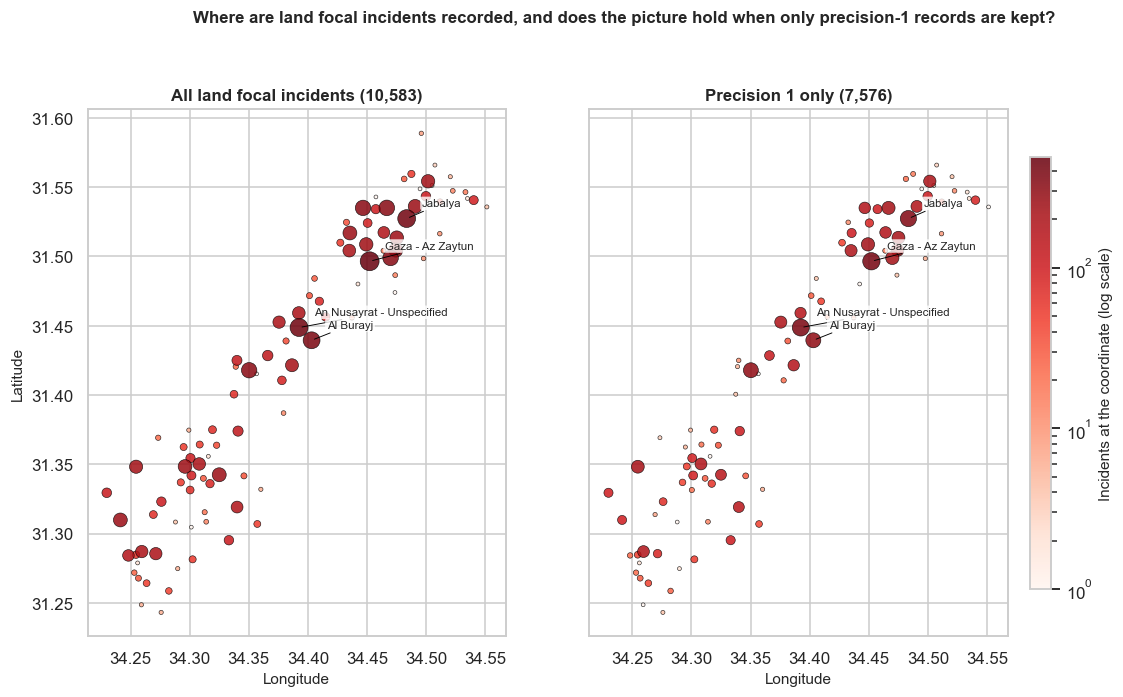

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.8), sharex=True, sharey=True)
vmax = sites_full.events.max()
for ax, sites, title in [(axes[0], sites_full, f"All land focal incidents ({len(incidents):,})"),
                         (axes[1], sites_p1, f"Precision 1 only ({len(inc_p1):,})")]:
    s = sites.sort_values("events")
    sc = ax.scatter(s.longitude, s.latitude, s=6 + s.events * 0.3, c=s.events, cmap="Reds", norm=LogNorm(vmin=1, vmax=vmax),
                    edgecolor="black", linewidth=0.4, alpha=0.85)
    ax.set_title(title); ax.set_xlabel("Longitude")
    ax.set_aspect(1 / np.cos(np.radians(31.45))); ax.grid(True)
    for _, r in sites.head(4).iterrows():
        ax.annotate(r.location, (r.longitude, r.latitude), textcoords="offset points", xytext=(10, 8), fontsize=7.5,
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8),
                    arrowprops=dict(arrowstyle="-", lw=0.6, color="black"))
axes[0].set_ylabel("Latitude")
fig.suptitle("Where are land focal incidents recorded, and does the picture hold when only precision-1 records are kept?", fontsize=11, fontweight="bold")
cb = fig.colorbar(sc, ax=axes, shrink=0.75, pad=0.02); cb.set_label("Incidents at the coordinate (log scale)")
plt.show()

**Interpretation.** The 10,583 incidents sit on only 101 coordinate pairs along a narrow north-east to south-west strip, with the largest bubbles in Gaza City (Az Zaytun, Sheikh Radwan, Shujaiyya), Jabalya, and the central towns of An Nusayrat, Al Burayj and Deir al Balah (BQ3). The precision-1 map (7,576 incidents, 95 coordinates) keeps the same overall shape but loses 6 small coordinates (41 incidents) and visibly thins the southern part of the strip (BQ5). There is no basemap and coordinates repeat for named places, so this shows recorded concentrations and not exact attack points or borders.

### Chart 11 — Which coordinates hold the most incidents, and how unevenly are incidents spread?

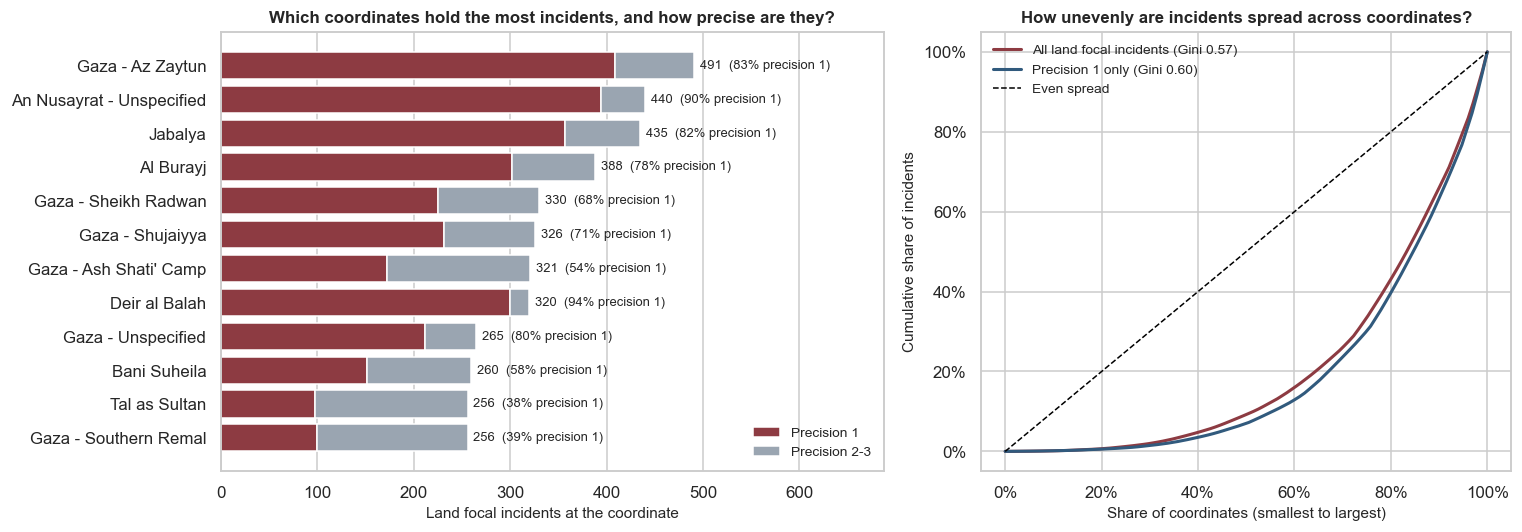

In [23]:
top12 = sites_full.head(12).iloc[::-1].copy()
top12["p1_events"] = (top12.events * top12.precision1_share).round()
top12["other_events"] = top12.events - top12.p1_events

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.barh(top12.location, top12.p1_events, color=C_FOCAL, label="Precision 1")
ax.barh(top12.location, top12.other_events, left=top12.p1_events, color=C_GREY, label="Precision 2-3")
for y, (_, r) in enumerate(top12.iterrows()):
    ax.text(r.events + 6, y, f"{int(r.events)}  ({r.precision1_share:.0%} precision 1)", va="center", fontsize=8.5)
ax.set_xlim(0, top12.events.max() * 1.4)
ax.set_xlabel("Land focal incidents at the coordinate"); ax.set_title("Which coordinates hold the most incidents, and how precise are they?")
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)

ax = axes[1]
for sites, lab, col in [(sites_full, "All land focal incidents", C_FOCAL), (sites_p1, "Precision 1 only", C_OTHER)]:
    v = np.sort(sites.events.to_numpy())
    ax.plot(np.r_[0, np.arange(1, len(v) + 1) / len(v)], np.r_[0, v.cumsum() / v.sum()], color=col, lw=2, label=f"{lab} (Gini {gini(v):.2f})")
ax.plot([0, 1], [0, 1], color="black", ls="--", lw=1, label="Even spread")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Share of coordinates (smallest to largest)"); ax.set_ylabel("Cumulative share of incidents")
ax.set_title("How unevenly are incidents spread across coordinates?"); ax.legend(frameon=False, loc="upper left"); ax.grid(True)
plt.tight_layout(); plt.show()

**Interpretation.** The 10 busiest coordinates hold 33.8% of all incidents and the top 20 hold 56.5% (Gini 0.57); with precision 1 only, these rise to 38.1% and 62.5% (Gini 0.61), so the restriction sharpens concentration (BQ3, BQ5). Among the 12 largest coordinates the precision-1 share runs from 38% to 94% (Tal as Sultan and Southern Remal are lowest, Deir al Balah highest), and 30 of the 101 coordinates are below 50% precision 1, so the precision filter removes places unevenly. A busy coordinate may simply be a well-documented place name, so concentration here is a statement about the records.

### 7.4 Preview of DBSCAN settings (for Phase 4)

**Question.** Phase 4 plans DBSCAN on land focal coordinates. Before it starts, how sensitive is the result to the radius and to `min_samples`, and does the precision-1 subset behave differently? Following the project rule, coordinates are converted to **radians** and the **haversine** distance is used (latitude and longitude are *not* standardised separately). This is a sensitivity preview, not a tuned model: there are no labels to validate against, and repeated coordinates matter because `min_samples` counts repeated incidents, not distinct places.

In [24]:
R_EARTH_KM = 6371.0088
def run_dbscan(df, eps_km, min_samples):
    X = np.radians(df[["latitude", "longitude"]].to_numpy())          # geographic coordinates in radians
    db = DBSCAN(eps=eps_km / R_EARTH_KM, min_samples=min_samples, metric="haversine", algorithm="ball_tree").fit(X)
    return db.labels_

rows = []
for subset, d in [("All land focal incidents", incidents), ("Precision 1 only", inc_p1)]:
    for ms in (10, 50):
        for eps in (0.25, 0.5, 1.0, 1.5, 2.0, 3.0):
            lab = run_dbscan(d, eps, ms)
            n_cl = len(set(lab)) - (1 if -1 in lab else 0)
            counts = pd.Series(lab[lab >= 0]).value_counts()
            rows.append({"subset": subset, "min_samples": ms, "eps_km": eps, "clusters": n_cl,
                         "noise_share": (lab == -1).mean(), "largest_cluster_share": counts.max() / len(d) if len(counts) else 0.0})
db_grid = pd.DataFrame(rows)
display(db_grid.round({"noise_share": 3, "largest_cluster_share": 3}))

,subset,min_samples,eps_km,clusters,noise_share,largest_cluster_share
0,All land focal incidents,10,0.25,81,0.007,0.046
1,All land focal incidents,10,0.50,81,0.006,0.046
2,All land focal incidents,10,1.00,58,0.005,0.081
3,All land focal incidents,10,1.50,30,0.003,0.220
4,All land focal incidents,10,2.00,19,0.001,0.424
5,All land focal incidents,10,3.00,1,0.000,1.000
6,All land focal incidents,50,0.25,55,0.070,0.046
7,All land focal incidents,50,0.50,55,0.070,0.046
8,All land focal incidents,50,1.00,43,0.042,0.081
9,All land focal incidents,50,1.50,20,0.028,0.220


### Chart 12 — How do the number of clusters, noise and the largest cluster change with the radius?

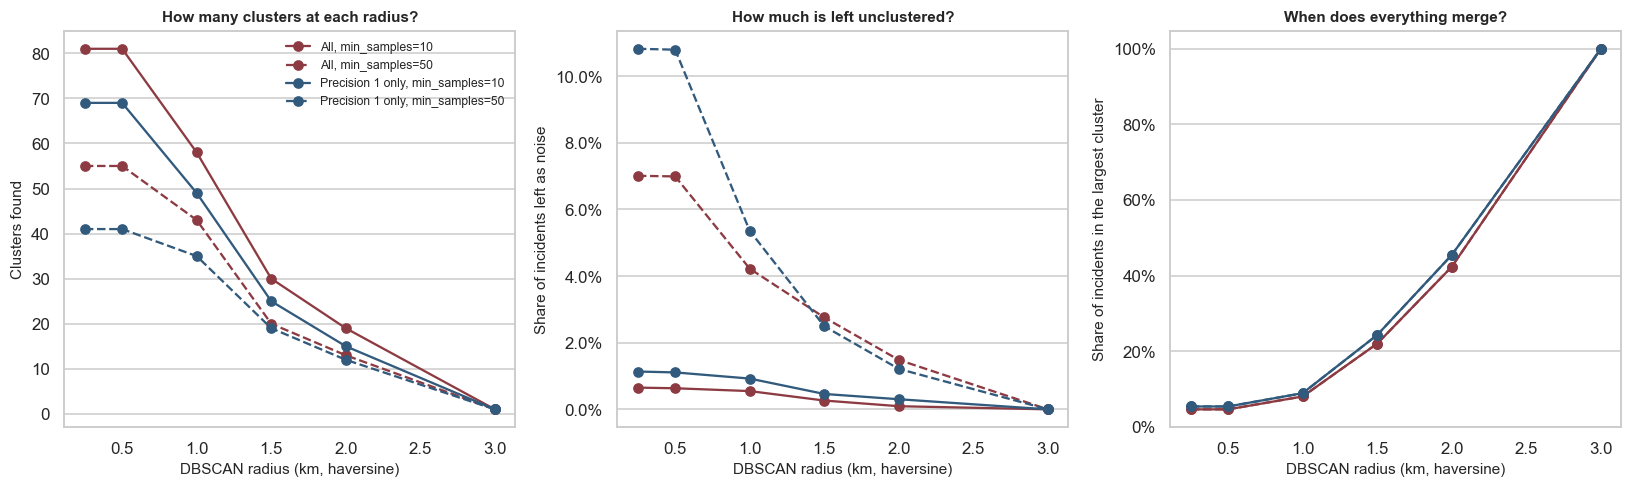

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
styles = {("All land focal incidents", 10): (C_FOCAL, "-"), ("All land focal incidents", 50): (C_FOCAL, "--"),
          ("Precision 1 only", 10): (C_OTHER, "-"), ("Precision 1 only", 50): (C_OTHER, "--")}
for ax, col, ylab, title in [(axes[0], "clusters", "Clusters found", "How many clusters at each radius?"),
                             (axes[1], "noise_share", "Share of incidents left as noise", "How much is left unclustered?"),
                             (axes[2], "largest_cluster_share", "Share of incidents in the largest cluster", "When does everything merge?")]:
    for (subset, ms), (c, ls) in styles.items():
        d = db_grid[(db_grid.subset == subset) & (db_grid.min_samples == ms)]
        ax.plot(d.eps_km, d[col], color=c, ls=ls, marker="o", label=f"{subset.replace(' land focal incidents', '')}, min_samples={ms}")
    if col != "clusters":
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlabel("DBSCAN radius (km, haversine)"); ax.set_ylabel(ylab); ax.set_title(title, fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** Radii of 0.25 and 0.5 km give identical results (81 clusters with `min_samples` 10) because the recorded coordinates are discrete places spaced further apart; the count then drops to 58 at 1 km, 30 at 1.5 km and 19 at 2 km, where the largest cluster already holds 42.4% of incidents, and at 3 km everything merges into a single cluster (BQ3). Raising `min_samples` to 50 leaves more incidents as noise (7.0% of all incidents, 10.8% at precision 1, at 0.5 km), and the precision-1 subset gives fewer clusters at every radius below 3 km (for example 69 against 81 at 0.5 km). A usable radius for Phase 4 therefore lies roughly between 1 and 2 km, and because 81 of the 101 coordinates already hold 10 or more incidents, DBSCAN here mostly groups named places, so Phase 4 should compare it with the district counts and consider weighting by incidents per coordinate.

## 8. Pattern register and handoff

The register collects what Sections 3 to 7 found, with the business question and what each pattern means for the next tasks. All numbers are repeated from the sections above.

In [26]:
register = pd.DataFrame([
    ("Imbalance", "Focal share is 16.2% before Oct 7 (63 of 389) and 47.6% after (10,651 of 22,364); Battles are 0 of 1,593 and Violence against civilians 784 of 790 after Oct 7", "BQ1, BQ5", "The earlier period and the extreme event types have too few minority cases to model on their own"),
    ("Suspicious values", "576 records report 24+ fatalities (2.2% of records) and hold 37.6% of all reported fatalities; 281 of them fall in Q4 2023", "BQ4", "Never delete them; run results with and without them"),
    ("Suspicious values", "13 complete weeks are flagged for focal events by a trailing 8-week median/MAD rule: lows in Mar and Jun 2024, Jan to Feb 2025 and Jun 2025, and highs (Mar 15 to Apr 5 and May 17, 2025) that mostly follow the early-2025 collapse", "BQ4", "A short trailing window scores a recovery as a spike; test a longer window"),
    ("Suspicious values", "50 of 475 scored district-weeks (10.5%) are flagged, most often in North Gaza (14.7%) and Gaza City (13.7%)", "BQ4", "The anomaly target is imbalanced; small districts are noisy"),
    ("Trend", "Weekly focal events show no lasting direction (rho 0.10), political-violence records fall (rho -0.55) and the focal share rises (rho 0.51; 34.0% in Jan 2024 to 67.0% in Sep 2025)", "BQ1, BQ4", "Use counts and shares as separate signals"),
    ("Seasonality", "No repeating calendar pattern: the monthly means of 2024 and 2025 are not aligned (rho -0.30) and no weekday stands out (ratio 1.11)", "BQ4", "Do not add seasonal terms; two years cannot test a yearly cycle"),
    ("Persistence", "Weekly focal events are autocorrelated (0.76 at lag 1, above the 95% band through lag 6) while week-to-week changes are not", "BQ4", "Supports previous-week and previous-four-week features"),
    ("Segments", "Gaza City holds 32.3% of known-district focal events; North Gaza is low in volume but the most bursty (0.83)", "BQ4", "Use per-district baselines, not one Gaza-wide threshold"),
    ("Clustering of weeks", "Three groups of weeks: 8 low weeks (Jan 18 to Mar 8, 2025), 51 weeks of a 2024 plateau and 44 higher-share weeks (the first weeks after Oct 7, 2023 and Mar to Sep 2025)", "BQ4", "Consider a regime indicator and treat the early weeks and the early-2025 gap with care"),
    ("Spatial concentration", "10,583 incidents sit on 101 distinct coordinates; the top 10 hold 33.8% and the top 20 hold 56.5%", "BQ3", "DBSCAN mostly groups named places; consider weighting by incidents per coordinate"),
    ("Precision", "Precision-1 keeps 95 of the 101 coordinates, but among the 12 largest coordinates its share runs from 38% to 94%; concentration rises (Gini 0.57 to 0.61)", "BQ3, BQ5", "Run DBSCAN on both the full and precision-1 subsets"),
    ("DBSCAN preview", "Clusters fall from 81 at 0.5 km to 19 at 2 km and merge into one at 3 km (min_samples 10)", "BQ3", "Try radii of about 1 to 2 km"),
], columns=["Pattern type", "What we saw", "Business question", "Phase 4 implication"])
with pd.option_context("display.max_colwidth", None):
    display(register)

,Pattern type,What we saw,Business question,Phase 4 implication
0,Imbalance,"Focal share is 16.2% before Oct 7 (63 of 389) and 47.6% after (10,651 of 22,364); Battles are 0 of 1,593 and Violence against civilians 784 of 790 after Oct 7","BQ1, BQ5",The earlier period and the extreme event types have too few minority cases to model on their own
1,Suspicious values,576 records report 24+ fatalities (2.2% of records) and hold 37.6% of all reported fatalities; 281 of them fall in Q4 2023,BQ4,Never delete them; run results with and without them
2,Suspicious values,"13 complete weeks are flagged for focal events by a trailing 8-week median/MAD rule: lows in Mar and Jun 2024, Jan to Feb 2025 and Jun 2025, and highs (Mar 15 to Apr 5 and May 17, 2025) that mostly follow the early-2025 collapse",BQ4,A short trailing window scores a recovery as a spike; test a longer window
3,Suspicious values,"50 of 475 scored district-weeks (10.5%) are flagged, most often in North Gaza (14.7%) and Gaza City (13.7%)",BQ4,The anomaly target is imbalanced; small districts are noisy
4,Trend,"Weekly focal events show no lasting direction (rho 0.10), political-violence records fall (rho -0.55) and the focal share rises (rho 0.51; 34.0% in Jan 2024 to 67.0% in Sep 2025)","BQ1, BQ4",Use counts and shares as separate signals
5,Seasonality,No repeating calendar pattern: the monthly means of 2024 and 2025 are not aligned (rho -0.30) and no weekday stands out (ratio 1.11),BQ4,Do not add seasonal terms; two years cannot test a yearly cycle
6,Persistence,"Weekly focal events are autocorrelated (0.76 at lag 1, above the 95% band through lag 6) while week-to-week changes are not",BQ4,Supports previous-week and previous-four-week features
7,Segments,Gaza City holds 32.3% of known-district focal events; North Gaza is low in volume but the most bursty (0.83),BQ4,"Use per-district baselines, not one Gaza-wide threshold"
8,Clustering of weeks,"Three groups of weeks: 8 low weeks (Jan 18 to Mar 8, 2025), 51 weeks of a 2024 plateau and 44 higher-share weeks (the first weeks after Oct 7, 2023 and Mar to Sep 2025)",BQ4,Consider a regime indicator and treat the early weeks and the early-2025 gap with care
9,Spatial concentration,"10,583 incidents sit on 101 distinct coordinates; the top 10 hold 33.8% and the top 20 hold 56.5%",BQ3,DBSCAN mostly groups named places; consider weighting by incidents per coordinate


### Handoff notes

**For Task 6 (business questions, Mark).**
- **BQ1:** the focal share rises from 16.2% to 47.6% (Task 2 and Task 4), but the earlier period has only 63 focal events, and the weekly share rises mainly because non-focal political violence falls (Section 5).
- **BQ3:** incidents concentrate on 101 coordinates, the top 20 hold 56.5%, and the picture is stable under the precision-1 restriction (Section 7.3).
- **BQ4:** persistence is strong, there is no seasonality, and Gaza City carries the most focal events while North Gaza is the most bursty (Sections 6 and 7.1).
- **BQ5:** results that change under the precision-1 restriction are the focal share (59.6% against 31.7%) and the level of concentration (Gini 0.57 to 0.61).

**For Task 7 (modelling, Kyle).**
- **Weekly anomaly detection:** use district-specific trailing baselines; an 8-week window scores the March 2025 recovery as spikes, so test a longer window or a recovery rule. About 10.5% of district-weeks are flagged, which is an imbalanced target for evaluation.
- **DBSCAN:** use haversine on radians, try radii of about 1 to 2 km, run on the full and precision-1 subsets, and decide how to treat repeated coordinates (101 distinct pairs for 10,583 incidents).
- **Features:** previous-week and previous-four-week focal counts are justified by the autocorrelation; seasonal terms are not.
- **Imbalance:** the earlier period and the extreme event types have very small minority classes (Section 3), and flagged high-fatality records (576) should be tested with and without.

### Limitations
- ACLED is a recorded-event dataset; reporting coverage can change over time and place, so a trend, a gap or a cluster can reflect documentation as well as events.
- Fatalities are reported event totals and do not identify civilian deaths; a zero can mean no figure was recorded.
- Two years of weekly data cannot support a test of yearly seasonality, and the rank-correlation and autocorrelation values ignore the fact that neighbouring weeks are related.
- Robust z-scores, k-means groups and the DBSCAN preview are screening and description tools without ground truth; their settings were chosen to describe the data, not to optimise anything.
- Coordinates repeat for named places and have varying precision, so spatial results describe recorded concentrations, not exact points.
- Findings describe a historical snapshot (Jan 2022 to Sep 2025), not current conditions.

### Reproducibility checklist
- [ ] The consistency table in Section 2 shows `True` in every row.
- [ ] `random_state=42` is used for k-means, and DBSCAN is deterministic, so reruns give the same numbers.
- [ ] Packages: numpy, pandas, matplotlib, seaborn, scipy (from the Phase 2 requirements) plus scikit-learn.
- [ ] The incomplete week (Sep 27, 2025) is shown but not scored.

### References
1. Group 7. *Phase 1: Dataset Selection and Business Problem* (BQ1 to BQ5).
2. Group 7. *Phase 2: Data Preprocessing* (focal-event rule, periods, `data/processed/` outputs).
3. Group 7. *Phase 3 notebooks:* univariate template, bivariate and multivariate (Charts 1 to 11), hypothesis testing (Hypotheses A and B).
4. Iglewicz, B. and Hoaglin, D. (1993). *How to Detect and Handle Outliers* (modified z-score and the 3.5 cut-off).
5. Ester, M., Kriegel, H.-P., Sander, J., Xu, X. (1996). A density-based algorithm for discovering clusters (DBSCAN).
6. scikit-learn documentation: `DBSCAN`, `KMeans`, `silhouette_score`.
7. ACLED. Codebook, definitions and interpretation limitations.
8. DS312. *Final Project Guide* and *Phase 3 EDA Guide (Group 7)*.